# Etapa 1: abstenção eleitoral no Brasil (TSE 2018–2024 + IBGE)

Este notebook reúne a Etapa 1 do projeto. A análise exploratória (seção 2) vem antes da limpeza: o objetivo aqui é conhecer os dados da camada bronze e listar os problemas que a Etapa 3 vai tratar. A seção termina com uma lista priorizada de problemas de qualidade, e cada item vira uma linha do log de limpeza.

Documentos de apoio: `reports/dicionario_dados.md` (domínios e sentinelas) e `reports/ficha_proposta.md` (perguntas de pesquisa).

## 1. Configuração

A camada bronze do TSE tem 31,6 milhões de linhas, todas as colunas em texto. Nada disso é carregado inteiro no pandas: as consultas rodam no DuckDB direto sobre o Parquet particionado (`ano=AAAA/SG_UF=XX`), e só os resultados agregados viram `DataFrame`. A coluna `tipo_eleicao` não existe na fonte e é derivada do ano (2018 e 2022 são eleições gerais; 2020 e 2024, municipais).

In [1]:
import sys
import time
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.agregacao import taxa_abstencao
from src.config import ANOS, BRONZE, SENTINELAS

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if abs(v) >= 1000 else f"{v:.4g}")
sns.set_theme(style="whitegrid")

con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
TSE_GLOB = (BRONZE / "tse_parquet" / "**" / "*.parquet").as_posix()
con.execute(f'''
    CREATE OR REPLACE VIEW tse AS
    SELECT *, CASE WHEN ano IN (2018, 2022) THEN 'geral' ELSE 'municipal' END AS tipo_eleicao
    FROM read_parquet('{TSE_GLOB}', hive_partitioning = true)
''')
for nome in ["populacao_municipios", "pib_municipios", "municipios_ibge", "depara_tse_ibge"]:
    caminho = (BRONZE / "ibge" / f"{nome}.parquet").as_posix()
    con.execute(f"CREATE OR REPLACE VIEW {nome} AS SELECT * FROM read_parquet('{caminho}')")


def sql(consulta: str) -> pd.DataFrame:
    # Executa no DuckDB e devolve só o resultado (já agregado) como DataFrame.
    return con.sql(consulta).df()


COLUNAS = [c for c in sql("DESCRIBE tse").column_name if c not in ("ano", "tipo_eleicao")]
COLS_QT = [c for c in COLUNAS if c.startswith("QT_")]
COLS_CD = [c for c in COLUNAS if c.startswith("CD_")]
# Chave candidata da célula: ano, turno, local (UF, município, zona) e todas as dimensões de perfil (CD_*).
CHAVE = ["ano", "NR_TURNO", "SG_UF", "CD_MUNICIPIO", "NR_ZONA"] + [c for c in COLS_CD if c != "CD_MUNICIPIO"]
CHAVE_SEM_2024 = CHAVE[:9]  # sem cor/raça, quilombola, Libras, identidade de gênero e indígenas
print(f"{len(COLUNAS) + 1} colunas na view (incluindo as partições SG_UF e ano), {len(COLS_QT)} contagens QT_*")
print("Chave candidata:", ", ".join(CHAVE))

44 colunas na view (incluindo as partições SG_UF e ano), 15 contagens QT_*
Chave candidata: ano, NR_TURNO, SG_UF, CD_MUNICIPIO, NR_ZONA, CD_GENERO, CD_ESTADO_CIVIL, CD_FAIXA_ETARIA, CD_GRAU_ESCOLARIDADE, CD_COR_RACA, CD_QUILOMBOLA, CD_INTERPRETE_LIBRAS, CD_IDENTIDADE_GENERO, CD_IDIOMA_INDIGENA, CD_GRUPO_INDIGENA


## 2. Análise exploratória

### 2.1 Visão geral

Quantas linhas, UFs, municípios e zonas cada ano tem, e quantos turnos.

In [2]:
visao = sql('''
    SELECT ano, any_value(tipo_eleicao) AS tipo, count(*) AS linhas,
           count(DISTINCT SG_UF) AS ufs, count(DISTINCT CD_MUNICIPIO) AS municipios,
           count(DISTINCT SG_UF || '-' || NR_ZONA) AS zonas, count(DISTINCT NR_TURNO) AS turnos,
           count(*) FILTER (WHERE NR_TURNO = '2') AS linhas_2o_turno
    FROM tse GROUP BY ano ORDER BY ano
''')
visao["colunas"] = len(COLUNAS) + 1
print(f"Total: {visao.linhas.sum():,} linhas")
visao

Total: 31,633,820 linhas


,ano,tipo,linhas,ufs,municipios,zonas,turnos,linhas_2o_turno,colunas
0,2018,geral,8377682,28,5741,2645,2,4188841,44
1,2020,municipal,4644923,26,5568,2625,2,383161,44
2,2022,geral,8785738,28,5751,2637,2,4392869,44
3,2024,municipal,9825477,26,5569,2619,2,861020,44


A bronze tem 31.633.820 linhas e 44 colunas (42 do CSV mais as partições `SG_UF` e `ano`). O volume não acompanha o eleitorado: 2020 tem 4,6 milhões de linhas e 2024 tem 9,8 milhões, embora os dois anos tenham eleitorados parecidos (148 e 156 milhões de aptos). A diferença vem do 2º turno, que nas eleições gerais repete todas as células (4,2 e 4,4 milhões de linhas) e nas municipais cobre poucos municípios, e das seis colunas de perfil que só existem em 2024 e partem cada célula em mais linhas (ver 2.2).

Os 28 "UFs" de 2018 e 2022 são 26 estados, DF e `ZZ` (exterior). Nas municipais não há DF (Brasília não elege prefeito) nem exterior. Contando sem `ZZ`, os municípios são 5.570 nas gerais, 5.568 em 2020 e 5.569 em 2024.

#### Tipos inferidos × esperados

Na bronze, toda coluna é `VARCHAR`. A consulta abaixo testa, em todas as linhas, se cada coluna converte para inteiro (`TRY_CAST`), data ou hora sem perda, e compara com o tipo alvo da silver registrado no dicionário de dados.

In [3]:
# Tipo alvo de cada coluna, lido da tabela do dicionário de dados (coluna "tipo").
esperado = {}
for linha in (RAIZ / "reports" / "dicionario_dados.md").read_text(encoding="utf-8").splitlines():
    partes = [p.strip() for p in linha.strip().strip("|").split("|")]
    if len(partes) == 6 and partes[0] in COLUNAS:
        esperado[partes[0]] = partes[2]

agregados = []
for c in COLUNAS:
    agregados += [
        f'count(*) FILTER (WHERE {c} IS NOT NULL AND TRY_CAST({c} AS BIGINT) IS NULL) AS "{c}|nao_int"',
        f'min(TRY_CAST({c} AS BIGINT)) AS "{c}|min"',
        f'max(TRY_CAST({c} AS BIGINT)) AS "{c}|max"',
        f'approx_count_distinct({c}) AS "{c}|distintos"',
        f'count(*) FILTER (WHERE {c} IS NULL) AS "{c}|nulos"',
    ]
agregados += [
    "count(*) FILTER (WHERE try_strptime(DT_GERACAO, '%d/%m/%Y') IS NULL) AS \"DT_GERACAO|nao_data\"",
    "count(*) FILTER (WHERE try_strptime(HH_GERACAO, '%H:%M:%S') IS NULL) AS \"HH_GERACAO|nao_hora\"",
]
t0 = time.time()
r = sql("SELECT " + ", ".join(agregados) + " FROM tse").iloc[0]
print(f"varredura de {len(COLUNAS)} colunas em {time.time() - t0:.0f} s")


def inferir(c):
    if c == "DT_GERACAO" and r[f"{c}|nao_data"] == 0:
        return "data (dd/mm/aaaa)"
    if c == "HH_GERACAO" and r[f"{c}|nao_hora"] == 0:
        return "hora (hh:mm:ss)"
    if r[f"{c}|nao_int"] == 0:
        return "inteiro"
    return "texto"


def compativel(inferido, alvo):
    if alvo.startswith("int"):
        return inferido == "inteiro"
    if alvo == "date":
        return inferido.startswith("data")
    if alvo == "time":
        return inferido.startswith("hora")
    return True  # string/category aceitam qualquer texto


tipos = pd.DataFrame({
    "coluna": COLUNAS,
    "tipo_bronze": "VARCHAR",
    "tipo_inferido": [inferir(c) for c in COLUNAS],
    "tipo_esperado": [esperado.get(c, "?") for c in COLUNAS],
    "min_int": [r[f"{c}|min"] for c in COLUNAS],
    "max_int": [r[f"{c}|max"] for c in COLUNAS],
    "distintos_aprox": [int(r[f"{c}|distintos"]) for c in COLUNAS],
    "nulos": [int(r[f"{c}|nulos"]) for c in COLUNAS],
})
tipos["compativel"] = [compativel(i, e) for i, e in zip(tipos.tipo_inferido, tipos.tipo_esperado)]
LIMITES = {"int8": 127, "int16": 32_767, "int32": 2_147_483_647}
tipos["cabe_no_alvo"] = [
    (pd.isna(mx) or abs(mx) <= LIMITES.get(e, np.inf)) and (pd.isna(mn) or abs(mn) <= LIMITES.get(e, np.inf))
    for mn, mx, e in zip(tipos.min_int, tipos.max_int, tipos.tipo_esperado)
]
print(f"{(tipos.tipo_inferido == 'inteiro').sum()} colunas convertem para inteiro sem perda (incluindo CD_MUNICIPIO)")
print("colunas incompatíveis com o alvo:", tipos.loc[~tipos.compativel, "coluna"].tolist())
print("valores que não cabem no inteiro alvo:", tipos.loc[~tipos.cabe_no_alvo, "coluna"].tolist())
print("colunas com NULL:", tipos.loc[tipos.nulos > 0, "coluna"].tolist())
tipos

varredura de 43 colunas em 43 s
29 colunas convertem para inteiro sem perda (incluindo CD_MUNICIPIO)
colunas incompatíveis com o alvo: []
valores que não cabem no inteiro alvo: []
colunas com NULL: []


,coluna,tipo_bronze,tipo_inferido,tipo_esperado,min_int,max_int,distintos_aprox,nulos,compativel,cabe_no_alvo
0,DT_GERACAO,VARCHAR,data (dd/mm/aaaa),date,<NA>,<NA>,2,0,True,True
1,HH_GERACAO,VARCHAR,hora (hh:mm:ss),time,<NA>,<NA>,4,0,True,True
2,ANO_ELEICAO,VARCHAR,inteiro,int16,2018,2024,4,0,True,True
3,NR_TURNO,VARCHAR,inteiro,int8,1,2,2,0,True,True
4,CD_MUNICIPIO,VARCHAR,inteiro,string,19,99473,5594,0,True,True
5,NM_MUNICIPIO,VARCHAR,texto,string,<NA>,<NA>,5639,0,True,True
6,NR_ZONA,VARCHAR,inteiro,int16,1,428,430,0,True,True
7,CD_GENERO,VARCHAR,inteiro,int8,0,4,3,0,True,True
8,DS_GENERO,VARCHAR,texto,category,<NA>,<NA>,3,0,True,True
9,CD_ESTADO_CIVIL,VARCHAR,inteiro,int8,0,9,6,0,True,True


Todas as 43 colunas da bronze convertem para o tipo alvo sem perda: nenhuma tem `NULL`, as 29 colunas de código e de contagem aceitam `TRY_CAST` para inteiro em 100% das linhas, e os valores cabem no inteiro escolhido (o maior `QT_*` é 7.187, longe do limite de `int32`; `CD_GRUPO_INDIGENA` vai até 310 e precisa de `int32`, como o dicionário previa). `DT_GERACAO` e `HH_GERACAO` estão em `dd/mm/aaaa` e `hh:mm:ss` em todas as linhas.

`CD_MUNICIPIO` também passaria como inteiro, mas não deve: o código tem zeros à esquerda (o menor é `00019`) e a junção com o de-para usa a forma de 5 caracteres.

#### Memória por coluna

Uma amostra aleatória de 1 milhão de linhas (amostragem *reservoir*, semente fixa) vai para o pandas duas vezes: como texto, igual à bronze, e convertida para os tipos alvo. `memory_usage(deep=True)` mede o custo de cada coluna.

In [4]:
amostra = sql("SELECT * EXCLUDE (tipo_eleicao) FROM tse USING SAMPLE reservoir(1000000 ROWS) REPEATABLE (42)")
amostra = amostra.astype({c: "object" for c in amostra.columns if c != "ano"})  # texto puro, como na bronze

tipada = amostra.copy()
for c in COLUNAS:
    alvo = esperado.get(c, "string")
    if alvo.startswith("int"):
        tipada[c] = pd.to_numeric(tipada[c]).astype(alvo)
    elif alvo == "category":
        tipada[c] = tipada[c].astype("category")
    elif alvo == "date":
        tipada[c] = pd.to_datetime(tipada[c], format="%d/%m/%Y")

mem = pd.DataFrame({
    "texto_MB": amostra[COLUNAS].memory_usage(deep=True, index=False) / 2**20,
    "tipado_MB": tipada[COLUNAS].memory_usage(deep=True, index=False) / 2**20,
    "dtype_tipado": tipada[COLUNAS].dtypes.astype(str),
})
mem["reducao_%"] = 100 * (1 - mem.tipado_MB / mem.texto_MB)
tot = mem[["texto_MB", "tipado_MB"]].sum()
fator = visao.linhas.sum() / len(amostra)
print(f"Amostra de {len(amostra):,} linhas: {tot.texto_MB:,.0f} MB como texto -> {tot.tipado_MB:,.0f} MB tipada "
      f"({100 * (1 - tot.tipado_MB / tot.texto_MB):.0f}% menos)")
print(f"Extrapolando para {visao.linhas.sum():,} linhas: {tot.texto_MB * fator / 1024:,.1f} GB -> "
      f"{tot.tipado_MB * fator / 1024:,.1f} GB")
try:
    import psutil
    print(f"Memória RAM desta máquina: {psutil.virtual_memory().total / 2**30:,.1f} GB")
except ImportError:
    print("psutil indisponível: memória RAM da máquina não medida")
mem.sort_values("texto_MB", ascending=False).round(1).head(20)

Amostra de 1,000,000 linhas: 2,771 MB como texto -> 290 MB tipada (90% menos)
Extrapolando para 31,633,820 linhas: 85.6 GB -> 9.0 GB
Memória RAM desta máquina: 15.4 GB


,texto_MB,tipado_MB,dtype_tipado,reducao_%
DS_GRUPO_INDIGENA,103.9,1.9,category,98.2
DS_IDENTIDADE_GENERO,103.3,1,category,99.1
DS_IDIOMA_INDIGENA,103.2,1,category,99.1
DS_QUILOMBOLA,100.6,1,category,99.1
DS_INTERPRETE_LIBRAS,100.5,1,category,99.1
DS_COR_RACA,96.3,1,category,99
DS_GRAU_ESCOLARIDADE,91.4,1,category,99
NM_MUNICIPIO,74.6,74.6,object,0
DS_ESTADO_CIVIL,66.2,1,category,98.6
DS_FAIXA_ETARIA,65.4,1,category,98.5


Como texto, a amostra de 1 milhão de linhas ocupa 2.771 MB no pandas; com os tipos alvo, 290 MB (90% menos). Extrapolado para a base inteira, seria a diferença entre 85,6 GB e 9,0 GB. A bronze inteira em texto não cabe na memória desta máquina (15,4 GB de RAM, medida acima), o que justifica fazer as agregações no DuckDB e tipar as colunas na silver. Os rótulos `DS_*` são os que mais pesam como texto (60–100 MB cada) e caem para cerca de 1 MB como `category`. `NM_MUNICIPIO`, `HH_GERACAO` e `CD_MUNICIPIO` não mudam porque ficaram como texto; `CD_MUNICIPIO` e `NM_MUNICIPIO` podem virar `category` na silver.

### 2.2 Qualidade

#### Ausentes

Não há `NULL` na bronze, então "ausente" aqui quer dizer vazio ou sentinela. Contam como ausentes os valores de `SENTINELAS` (`src/config.py`), o rótulo `Inválido` da faixa etária e o código `0` em `CD_GENERO`, `CD_ESTADO_CIVIL` e `CD_GRAU_ESCOLARIDADE`, que o dicionário identificou como "não informado".

In [5]:
SENTINELA_ZERO = {"CD_GENERO", "CD_ESTADO_CIVIL", "CD_GRAU_ESCOLARIDADE"}
TEXTOS_AUSENTES = sorted({s.upper() for s in SENTINELAS} | {"INVÁLIDO"})
LISTA_AUSENTES = ", ".join("'" + s.replace("'", "''") + "'" for s in TEXTOS_AUSENTES)


def ausente(c: str) -> str:
    zero = f" OR {c} = '0'" if c in SENTINELA_ZERO else ""
    return f"({c} IS NULL OR trim({c}) = '' OR upper(trim({c})) IN ({LISTA_AUSENTES}){zero})"


pct = sql("SELECT ano, " + ", ".join(f'100 * avg({ausente(c)}::INT) AS "{c}"' for c in COLUNAS)
          + " FROM tse GROUP BY ano ORDER BY ano").set_index("ano").T
pct.columns = [f"% {a}" for a in pct.columns]
com_ausente = pct[pct.max(axis=1) > 0].sort_values(pct.columns[-1])
print(f"{len(COLUNAS) - len(com_ausente)} colunas sem nenhum ausente; {len(com_ausente)} com ausentes:")
com_ausente.round(3)

23 colunas sem nenhum ausente; 20 com ausentes:


,% 2018,% 2020,% 2022,% 2024
DS_FAIXA_ETARIA,0.066,0.053,0.044,0.017
CD_FAIXA_ETARIA,0.066,0.053,0.044,0.017
DS_GRAU_ESCOLARIDADE,0.604,0.442,0.353,0.129
CD_GRAU_ESCOLARIDADE,0.604,0.442,0.353,0.129
DS_GENERO,0.764,0.639,0.471,0.189
CD_GENERO,0.764,0.639,0.471,0.189
DS_ESTADO_CIVIL,1.222,0.966,0.723,0.285
CD_ESTADO_CIVIL,1.222,0.966,0.723,0.285
CD_IDENTIDADE_GENERO,100,100,100,43.85
DS_IDENTIDADE_GENERO,100,100,100,43.85


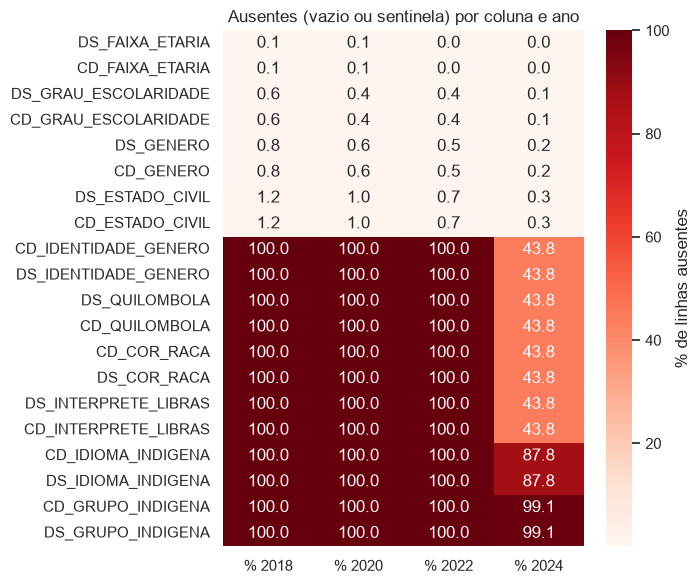

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(com_ausente, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% de linhas ausentes"}, ax=ax)
ax.set_title("Ausentes (vazio ou sentinela) por coluna e ano")
plt.tight_layout()
plt.show()

O percentual de linhas não diz quantos eleitores cada sentinela afeta. A tabela abaixo pondera pelos aptos do 1º turno nas quatro dimensões de perfil usadas nas perguntas.

In [7]:
perfis = {"CD_FAIXA_ETARIA": "-3", "CD_GENERO": "0", "CD_GRAU_ESCOLARIDADE": "0", "CD_ESTADO_CIVIL": "0"}
partes = [
    f'''SELECT '{c}' AS coluna, ano, count(*) FILTER (WHERE {c} = '{v}') AS linhas,
               sum(QT_APTOS::BIGINT) FILTER (WHERE {c} = '{v}') AS aptos_afetados,
               100 * sum(QT_APTOS::BIGINT) FILTER (WHERE {c} = '{v}') / sum(QT_APTOS::BIGINT) AS pct_aptos
        FROM tse WHERE NR_TURNO = '1' GROUP BY ano'''
    for c, v in perfis.items()
]
sentinela_aptos = sql(" UNION ALL ".join(partes) + " ORDER BY coluna, ano")
tot = sql("SELECT ano, " + ", ".join(f"count(*) FILTER (WHERE {c} = '{v}') AS \"{c} = {v}\"" for c, v in perfis.items())
          + " FROM tse GROUP BY ano ORDER BY ano").set_index("ano")
tot.loc["total"] = tot.sum()
print("Linhas com sentinela, todos os turnos:")
display(tot)
print("Aptos afetados e % dos aptos, 1º turno:")
sentinela_aptos.pivot(index="coluna", columns="ano", values=["aptos_afetados", "pct_aptos"]).round(4)

Linhas com sentinela, todos os turnos:


,CD_FAIXA_ETARIA = -3,CD_GENERO = 0,CD_GRAU_ESCOLARIDADE = 0,CD_ESTADO_CIVIL = 0
ano,,,,
2018,5558,63998,50562,102414
2020,2467,29678,20548,44883
2022,3868,41372,30970,63522
2024,1686,18529,12634,27963
total,13579,153577,114714,238782


Aptos afetados e % dos aptos, 1º turno:


aptos_afetados                      pct_aptos                     
ano                            2018   2020   2022   2024      2018   2020   2022   2024
coluna                                                                                 
CD_ESTADO_CIVIL              95,312 58,907 53,712 40,888    0.0647 0.0398 0.0343 0.0262
CD_FAIXA_ETARIA               2,910  2,169  1,990  1,488     0.002 0.0015 0.0013  0.001
CD_GENERO                    63,401 40,457 36,782 28,769     0.043 0.0274 0.0235 0.0185
CD_GRAU_ESCOLARIDADE         56,359 35,139 32,156 25,808    0.0383 0.0238 0.0206 0.0166

Há dois tipos de ausência.

- Colunas de perfil que só existem em 2024. Cor/raça, quilombola, Libras, identidade de gênero, idioma e grupo indígena são `-1` em 100% das linhas de 2018, 2020 e 2022. Em 2024 o quadro também é ruim: cor/raça está "não informada" em 43,8% das linhas, mas, ponderando pelos aptos, em 89,8% do eleitorado (ver a distribuição em 2.3). As linhas informadas são células pequenas, e o dado cobre só cerca de 10% dos eleitores. Em idioma e grupo indígena, `-1` (87,8% e 99,1% das linhas de 2024) inclui quem não é indígena, então ali a sentinela quer dizer também "não se aplica".
- Sentinelas nas dimensões usadas nas perguntas. Estado civil `0` (0,3% a 1,2% das linhas), gênero `0` (0,2% a 0,8%), escolaridade `0` (0,1% a 0,6%) e faixa etária `-3` (até 0,07%). Pesam pouco no eleitorado: no máximo 0,065% dos aptos (estado civil em 2018). Diminuem a cada eleição. Podem ser separadas como "não informado" sem mexer nos resultados.

#### Duplicados e chave da linha

Cada linha deveria ser uma célula única: ano, turno, UF, município, zona e perfil (todas as colunas `CD_*`). Três verificações:

1. a chave sem as colunas que só existem em 2024;
2. a chave completa;
3. duplicados exatos (todas as 44 colunas iguais), procurados dentro dos grupos repetidos da chave completa, já que um duplicado exato também repete a chave.

In [8]:
def chave_repetida(cols: list[str]) -> pd.DataFrame:
    k = ", ".join(cols)
    return sql(f'''
        SELECT ano, count(*) AS grupos_repetidos, sum(n) AS linhas_envolvidas, max(n) AS max_linhas_no_grupo
        FROM (SELECT {k}, count(*) AS n FROM tse GROUP BY {k} HAVING count(*) > 1)
        GROUP BY ano ORDER BY ano''')


t0 = time.time()
rep_sem_2024 = chave_repetida(CHAVE_SEM_2024)
k = ", ".join(CHAVE)
con.execute(f'''
    CREATE OR REPLACE TEMP TABLE grupos_rep AS
    SELECT {k}, count(*) AS n, min(QT_APTOS::INT) AS menor_aptos, max(QT_APTOS::INT) AS maior_aptos,
           sum(QT_APTOS::INT) AS aptos
    FROM tse GROUP BY {k} HAVING count(*) > 1''')
con.execute(f"CREATE OR REPLACE TEMP TABLE linhas_rep AS SELECT t.* EXCLUDE (tipo_eleicao) FROM tse t SEMI JOIN grupos_rep USING ({k})")
todas = ", ".join(COLUNAS + ["ano"])
exatos = sql(f'''
    SELECT ano, count(*) AS grupos_exatos, sum(n - 1) AS linhas_excedentes
    FROM (SELECT {todas}, count(*) AS n FROM linhas_rep GROUP BY {todas} HAVING count(*) > 1)
    GROUP BY ano ORDER BY ano''')
rep_completa = sql('''
    SELECT ano, count(*) AS grupos_repetidos, sum(n) AS linhas_envolvidas, max(n) AS max_linhas_no_grupo,
           median(menor_aptos) AS mediana_menor_parte, avg((menor_aptos = 1)::INT) * 100 AS pct_menor_parte_1_eleitor,
           sum(aptos) AS aptos_nos_grupos
    FROM grupos_rep GROUP BY ano ORDER BY ano''')
print(f"{time.time() - t0:.0f} s")
dup = (rep_sem_2024.set_index("ano").add_suffix(" (chave sem 2024)")
       .join(rep_completa.set_index("ano").add_suffix(" (chave completa)"))
       .join(exatos.set_index("ano")))
dup.T

53 s


ano,2018,2020,2022,2024
grupos_repetidos (chave sem 2024),"15,096","12,664","60,778","2,068,668"
linhas_envolvidas (chave sem 2024),"30,192","25,328","121,556","7,303,768"
max_linhas_no_grupo (chave sem 2024),2,2,2,58
grupos_repetidos (chave completa),"15,096","12,664","60,778","40,574"
linhas_envolvidas (chave completa),"30,192","25,328","121,556","81,149"
max_linhas_no_grupo (chave completa),2,2,2,3
mediana_menor_parte (chave completa),1,1,1,1
pct_menor_parte_1_eleitor (chave completa),93.96,91.79,83.74,85.38
aptos_nos_grupos (chave completa),"9,707,688","8,710,485","29,025,556","18,489,166"
grupos_exatos,21,21,276,"1,661"


Um exemplo de grupo repetido pela chave completa, e um teste: se as linhas repetidas fossem cópias acidentais da carga, não haveria motivo para o mesmo desdobramento aparecer igual nos dois turnos das eleições gerais, em que o eleitorado de cada célula é o mesmo.

In [9]:
exemplo = sql(f'''
    SELECT ano, NR_TURNO, SG_UF, CD_MUNICIPIO, NR_ZONA, CD_GENERO, CD_ESTADO_CIVIL, CD_FAIXA_ETARIA,
           CD_GRAU_ESCOLARIDADE, QT_APTOS, QT_COMPARECIMENTO, QT_ABSTENCAO
    FROM linhas_rep WHERE ano = 2018 AND NR_TURNO = '1'
    ORDER BY {k} LIMIT 6''')
display(exemplo)

# O desdobramento se repete nos dois turnos de 2018 e 2022?
chave_sem_turno = ", ".join(c for c in CHAVE if c != "NR_TURNO")
espelho = sql(f'''
    WITH g AS (SELECT * FROM grupos_rep WHERE ano IN (2018, 2022))
    SELECT g1.ano, count(*) AS grupos_1o_turno,
           count(g2.ano) AS com_mesmo_grupo_no_2o,
           count(*) FILTER (WHERE g1.n = g2.n AND g1.menor_aptos = g2.menor_aptos AND g1.aptos = g2.aptos) AS identicos_no_2o
    FROM g g1 LEFT JOIN g g2 USING ({chave_sem_turno})
    WHERE g1.NR_TURNO = '1' AND (g2.NR_TURNO = '2' OR g2.NR_TURNO IS NULL)
    GROUP BY g1.ano ORDER BY g1.ano''')
espelho

,ano,NR_TURNO,SG_UF,CD_MUNICIPIO,NR_ZONA,CD_GENERO,CD_ESTADO_CIVIL,CD_FAIXA_ETARIA,CD_GRAU_ESCOLARIDADE,QT_APTOS,QT_COMPARECIMENTO,QT_ABSTENCAO
0,2018,1,AC,01074,4,2,1,1900,5,560,438,122
1,2018,1,AC,01074,4,2,1,1900,5,1,1,0
2,2018,1,AC,01139,7,2,1,1800,6,1,0,1
3,2018,1,AC,01139,7,2,1,1800,6,19,16,3
4,2018,1,AC,01392,1,2,1,1600,5,275,241,34
5,2018,1,AC,01392,1,2,1,1600,5,1,1,0


,ano,grupos_1o_turno,com_mesmo_grupo_no_2o,identicos_no_2o
0,2018,7548,7548,7548
1,2022,30389,30389,30389


A combinação (UF, município, zona, perfil) não é única por turno, e isso não se resolve com as colunas disponíveis.

- Com a chave sem as colunas de 2024, o ano de 2024 tem 2,07 milhões de grupos repetidos (até 58 linhas por grupo). Isso é esperado: em 2024 cor/raça, identidade de gênero etc. subdividem a célula. Com a chave completa, 2024 cai para 40.574 grupos.
- Mesmo com a chave completa sobram 15.096 (2018), 12.664 (2020), 60.778 (2022) e 40.574 (2024) grupos com 2 ou 3 linhas. As linhas do grupo só diferem nas contagens. Em 84% a 94% dos grupos, a parte menor tem 1 eleitor (mediana 1), como no exemplo acima (560 + 1 aptos).
- Os "duplicados exatos" (21, 21, 276 e 1.661 linhas excedentes) estão todos dentro desses grupos: são casos em que as duas partes têm por acaso as mesmas contagens, quase sempre 1 eleitor cada.

O teste do espelho indica que as partes são registros legítimos da fonte: nas eleições gerais, os 7.548 grupos de 2018 e os 30.389 de 2022 aparecem idênticos no 2º turno, com o mesmo número de linhas e os mesmos aptos. A fonte parece separar a célula por algum atributo que não veio no arquivo. Apagar os duplicados exatos tiraria eleitores reais da base (1.979 linhas). O tratamento correto é somar as contagens pela chave completa, o que deixa a chave única sem alterar nenhum total.

#### Valores fora do domínio

O domínio de referência é o do LEIAME do TSE (códigos válidos), mais as duas sentinelas que o próprio LEIAME prevê (`-1` para `#NULO` e `-3` para `#NE`). Tudo o que fica fora dessa lista aparece abaixo, por ano.

In [10]:
UFS = {"AC", "AL", "AM", "AP", "BA", "CE", "DF", "ES", "GO", "MA", "MG", "MS", "MT", "PA", "PB", "PE", "PI",
       "PR", "RJ", "RN", "RO", "RR", "RS", "SC", "SE", "SP", "TO"}
SIM_NAO = {"1", "2"}
DOMINIO_LEIAME = {
    "NR_TURNO": {"1", "2"},
    "CD_GENERO": {"2", "4"},
    "CD_ESTADO_CIVIL": {"1", "3", "5", "7", "9"},
    "CD_GRAU_ESCOLARIDADE": {str(i) for i in range(1, 9)},
    "CD_FAIXA_ETARIA": {"1600", "1700", "1800", "1900", "2000", "2124", "9999"} | {f"{a}{a + 4}" for a in range(25, 100, 5)},
    "CD_COR_RACA": {"1", "2", "3", "4", "5", "6"},
    "CD_QUILOMBOLA": SIM_NAO,
    "CD_INTERPRETE_LIBRAS": SIM_NAO,
    "CD_IDENTIDADE_GENERO": {"1", "2", "3"},
    "CD_IDIOMA_INDIGENA": SIM_NAO,
    "SG_UF": UFS | {"ZZ", "BR", "VT"},
}
SENTINELAS_LEIAME = {"-1", "-3"}


def lista_sql(valores):
    return ", ".join(f"'{v}'" for v in sorted(valores))


partes = [
    f"SELECT '{c}' AS coluna, ano, {c} AS valor, count(*) AS linhas FROM tse "
    f"WHERE {c} NOT IN ({lista_sql(dom | SENTINELAS_LEIAME)}) GROUP BY ALL"
    for c, dom in DOMINIO_LEIAME.items()
]
partes += [
    "SELECT 'CD_MUNICIPIO (5 dígitos)', ano, CD_MUNICIPIO, count(*) FROM tse WHERE NOT regexp_full_match(CD_MUNICIPIO, '[0-9]{5}') GROUP BY ALL",
    "SELECT 'NR_ZONA (inteiro > 0)', ano, NR_ZONA, count(*) FROM tse WHERE TRY_CAST(NR_ZONA AS INT) IS NULL OR NR_ZONA::INT <= 0 GROUP BY ALL",
    "SELECT 'ANO_ELEICAO = ano', ano, ANO_ELEICAO, count(*) FROM tse WHERE ANO_ELEICAO <> ano::VARCHAR GROUP BY ALL",
    "SELECT 'CD_GRUPO_INDIGENA (inteiro)', ano, CD_GRUPO_INDIGENA, count(*) FROM tse WHERE TRY_CAST(CD_GRUPO_INDIGENA AS INT) IS NULL GROUP BY ALL",
]
partes += [f"SELECT '{c} < 0', ano, 'negativo', count(*) FROM tse WHERE {c}::BIGINT < 0 GROUP BY ALL" for c in COLS_QT]
fora = sql(" UNION ALL ".join(partes))
fora_dom = (fora.pivot_table(index=["coluna", "valor"], columns="ano", values="linhas", aggfunc="sum", fill_value=0)
            .reset_index())
fora_dom

ano,coluna,valor,2018,2020,2022,2024
0,CD_ESTADO_CIVIL,0,102414,44883,63522,27963
1,CD_GENERO,0,63998,29678,41372,18529
2,CD_GRAU_ESCOLARIDADE,0,50562,20548,30970,12634


Cada código `CD_*` deveria ter um único rótulo `DS_*` e vice-versa. A verificação também lista os rótulos com caixa mista, já que o restante da base usa maiúsculas.

In [11]:
pares = []
for cd in [c for c in COLS_CD if c != "CD_MUNICIPIO"]:
    ds = "DS_" + cd[3:]
    pares.append(f'''SELECT '{cd}' AS codigo, count(DISTINCT {cd}) AS codigos, count(DISTINCT {ds}) AS rotulos,
        count(DISTINCT {cd} || '|' || {ds}) AS pares,
        count(DISTINCT {ds}) FILTER (WHERE {ds} <> upper({ds})) AS rotulos_caixa_mista,
        string_agg(DISTINCT {ds}, ' / ') FILTER (WHERE {ds} <> upper({ds})) AS exemplos_caixa_mista FROM tse''')
pares.append('''SELECT 'CD_MUNICIPIO (por ano)', max(c), max(d), max(p), 0, NULL FROM (
    SELECT ano, count(DISTINCT CD_MUNICIPIO) c, count(DISTINCT NM_MUNICIPIO) d,
           count(DISTINCT CD_MUNICIPIO || '|' || NM_MUNICIPIO) p FROM tse GROUP BY ano)''')
cd_ds = sql(" UNION ALL ".join(pares))
cd_ds["um_para_um"] = (cd_ds.codigos == cd_ds.pares) & (cd_ds.rotulos == cd_ds.pares)
cd_ds

,codigo,codigos,rotulos,pares,rotulos_caixa_mista,exemplos_caixa_mista,um_para_um
0,CD_GENERO,3,3,3,0,NaN,True
1,CD_ESTADO_CIVIL,6,6,6,0,NaN,True
2,CD_FAIXA_ETARIA,23,23,23,23,16 anos / 80 a 84 anos / 21 a 24 anos / 55 a 59 anos / 7...,True
3,CD_GRAU_ESCOLARIDADE,9,9,9,0,NaN,True
4,CD_COR_RACA,6,6,6,5,Amarela / Parda / Branca / Preta / Indígena,True
5,CD_QUILOMBOLA,3,3,3,0,NaN,True
6,CD_INTERPRETE_LIBRAS,3,3,3,0,NaN,True
7,CD_IDENTIDADE_GENERO,4,4,4,3,Transgênero / Prefere não informar / Cisgênero,True
8,CD_IDIOMA_INDIGENA,3,3,3,0,NaN,True
9,CD_GRUPO_INDIGENA,298,298,298,297,Fulni-ô / Potiguara / Makuxí / Tembé / Torá / Kaiabi / M...,True


Contra o domínio do LEIAME, só aparecem fora os códigos `0` de estado civil (238.782 linhas nos quatro anos), gênero (153.577) e escolaridade (114.714), que o LEIAME não lista e que a base rotula como NÃO INFORMADO. Não há turno, UF, faixa etária, cor/raça ou indicador sim/não fora da lista, nem município com formato diferente de 5 dígitos, zona inválida, `ANO_ELEICAO` diferente da partição ou contagem negativa. Também não há idade negativa: `CD_FAIXA_ETARIA` só traz os códigos de faixa do LEIAME e a sentinela `-3` (Inválido), que marca idade inválida. As UFs `BR` e `VT`, que o LEIAME prevê, não aparecem.

Todo código `CD_*` tem exatamente um rótulo `DS_*`. A forma dos rótulos varia: faixa etária vem em minúsculas ("16 anos", "Inválido"), e cor/raça, identidade de gênero e grupo indígena misturam caixa ("Branca", "Cisgênero") com o NÃO INFORMADO em maiúsculas. No município, cada código tem um único nome por ano, mas há 5.751 códigos para 5.466 nomes: nomes se repetem entre UFs, então a junção tem de ser feita pelo código.

#### Consistência entre contagens

As contagens `QT_*` se decompõem umas nas outras: aptos = comparecimento + abstenção, e cada total = parte facultativa + parte obrigatória. A legislação também fixa quem tem voto facultativo (16–17 anos, 70 anos ou mais e analfabetos), o que dá um teste cruzado entre perfil e contagem.

In [12]:
i = lambda c: f"{c}::BIGINT"
regras = {
    "aptos = comparecimento + abstenção": f"{i('QT_APTOS')} <> {i('QT_COMPARECIMENTO')} + {i('QT_ABSTENCAO')}",
    "comparecimento = facultativo + obrigatório": f"{i('QT_COMPARECIMENTO')} <> {i('QT_COMPAREC_FACULTATIVO')} + {i('QT_COMPAREC_OBRIGATORIO')}",
    "abstenção = facultativo + obrigatório": f"{i('QT_ABSTENCAO')} <> {i('QT_ABST_FACULTATIVO')} + {i('QT_ABST_OBRIGATORIO')}",
    "comparec. deficiência = fac. + obrig.": f"{i('QT_COMPARECIMENTO_DEFICIENCIA')} <> {i('QT_COMPAREC_DEFIC_FACULTATIVO')} + {i('QT_COMPAREC_DEFIC_OBRIGATORIO')}",
    "abst. deficiência = fac. + obrig.": f"{i('QT_ABSTENCAO_DEFICIENCIA')} <> {i('QT_ABST_DEFIC_FACULTATIVO')} + {i('QT_ABST_DEFIC_OBRIGATORIO')}",
    "abst. deficiência <= abstenção": f"{i('QT_ABSTENCAO_DEFICIENCIA')} > {i('QT_ABSTENCAO')}",
    "abst. TTE <= abstenção": f"{i('QT_ABSTENCAO_TTE')} > {i('QT_ABSTENCAO')}",
    "aptos > 0": f"{i('QT_APTOS')} <= 0",
    "facultativo só para 16-17, 70+ ou analfabeto": (
        "CD_FAIXA_ETARIA::INT BETWEEN 1800 AND 6569 AND CD_GRAU_ESCOLARIDADE <> '1' "
        f"AND {i('QT_COMPAREC_FACULTATIVO')} + {i('QT_ABST_FACULTATIVO')} > 0"),
    "obrigatório nunca para 16-17, 70+ ou analfabeto": (
        "(CD_FAIXA_ETARIA IN ('1600', '1700') OR CD_FAIXA_ETARIA::INT >= 7074 OR CD_GRAU_ESCOLARIDADE = '1') "
        f"AND {i('QT_COMPAREC_OBRIGATORIO')} + {i('QT_ABST_OBRIGATORIO')} > 0"),
    "16-17 anos com superior completo (implausível)": "CD_FAIXA_ETARIA IN ('1600', '1700') AND CD_GRAU_ESCOLARIDADE = '8'",
}
consist = sql("SELECT ano, " + ", ".join(f'count(*) FILTER (WHERE {cond}) AS "{nome}"' for nome, cond in regras.items())
              + " FROM tse GROUP BY ano ORDER BY ano").set_index("ano").T
consist.columns = [f"violações {a}" for a in consist.columns]
consist

,violações 2018,violações 2020,violações 2022,violações 2024
aptos = comparecimento + abstenção,0,0,0,0
comparecimento = facultativo + obrigatório,0,0,0,0
abstenção = facultativo + obrigatório,0,0,0,0
comparec. deficiência = fac. + obrig.,0,0,0,0
abst. deficiência = fac. + obrig.,0,0,0,0
abst. deficiência <= abstenção,0,0,0,0
abst. TTE <= abstenção,0,0,0,0
aptos > 0,0,0,0,0
"facultativo só para 16-17, 70+ ou analfabeto",0,0,0,0
"obrigatório nunca para 16-17, 70+ ou analfabeto",0,0,0,0


In [13]:
# Em eleições gerais o eleitorado do 2º turno deve ser o do 1º, município a município.
turnos_mun = sql('''
    SELECT ano, CD_MUNICIPIO,
           sum(QT_APTOS::BIGINT) FILTER (WHERE NR_TURNO = '1') AS aptos_t1,
           sum(QT_APTOS::BIGINT) FILTER (WHERE NR_TURNO = '2') AS aptos_t2
    FROM tse GROUP BY ALL''')
turnos_mun.groupby("ano").agg(
    municipios=("CD_MUNICIPIO", "size"),
    com_2o_turno=("aptos_t2", "count"),
    aptos_t2_diferente_de_t1=("aptos_t2", lambda s: int((s.notna() & (s != turnos_mun.loc[s.index, "aptos_t1"])).sum())),
)

,municipios,com_2o_turno,aptos_t2_diferente_de_t1
ano,,,
2018,5741,5741,0
2020,5568,58,0
2022,5751,5751,0
2024,5569,51,0


As contagens são consistentes em todas as 31,6 milhões de linhas: zero violações em todas as identidades (aptos = comparecimento + abstenção, decomposição facultativo/obrigatório, deficiência e TTE contidos na abstenção). As regras de voto facultativo também batem: não há eleitor facultativo entre 18 e 69 anos alfabetizado, nem obrigatório entre 16–17, 70+ ou analfabetos. Nada a corrigir aqui; as regras podem virar testes de regressão da silver.

Um caso falha no teste de plausibilidade: há eleitores de 16 e 17 anos com superior completo (246, 128, 1.074 e 159 linhas, somando os dois turnos). É pouco, e o mais provável é escolaridade declarada errada no cadastro.

Nos turnos, o eleitorado de cada município no 2º turno é igual ao do 1º em 100% dos casos, tanto nas gerais (todos os municípios) quanto nas municipais (58 municípios em 2020, 51 em 2024). Isso confirma que somar `QT_APTOS` entre turnos conta o mesmo eleitor duas vezes.

#### Cobertura de municípios e junção com o IBGE

Os códigos do TSE não são os do IBGE; a ponte é o de-para (`depara_tse_ibge`). A tabela separa, por ano, os códigos do exterior (`ZZ`), os que têm par no de-para e os que não têm, e conta os municípios do IBGE sem eleição no ano.

In [14]:
cobertura = sql('''
    WITH m AS (SELECT DISTINCT ano, SG_UF, CD_MUNICIPIO, NM_MUNICIPIO FROM tse)
    SELECT m.ano,
           count(*) FILTER (WHERE SG_UF = 'ZZ') AS exterior_zz,
           count(*) FILTER (WHERE SG_UF <> 'ZZ') AS municipios_br,
           count(*) FILTER (WHERE SG_UF <> 'ZZ' AND d.cd_municipio_ibge IS NOT NULL) AS com_depara,
           count(*) FILTER (WHERE SG_UF <> 'ZZ' AND d.cd_municipio_ibge IS NULL) AS sem_depara,
           string_agg(CASE WHEN SG_UF <> 'ZZ' AND d.cd_municipio_ibge IS NULL
                           THEN SG_UF || ' ' || CD_MUNICIPIO || ' ' || NM_MUNICIPIO END, '; ') AS quais_sem_depara,
           count(*) FILTER (WHERE CD_MUNICIPIO LIKE '99%' AND SG_UF <> 'ZZ') AS codigos_99xxx_br
    FROM m LEFT JOIN depara_tse_ibge d ON d.cd_municipio_tse = m.CD_MUNICIPIO
    GROUP BY m.ano ORDER BY m.ano''')
ibge_sem_eleicao = sql('''
    WITH m AS (SELECT DISTINCT ano, CD_MUNICIPIO FROM tse WHERE SG_UF <> 'ZZ')
    SELECT a.ano, count(*) AS ibge_sem_eleicao,
           string_agg(i.nm_municipio || '/' || i.sg_uf, '; ') AS quais
    FROM municipios_ibge i
    CROSS JOIN (SELECT DISTINCT ano FROM m) a
    LEFT JOIN depara_tse_ibge d USING (cd_municipio_ibge)
    WHERE NOT EXISTS (SELECT 1 FROM m WHERE m.ano = a.ano AND m.CD_MUNICIPIO = d.cd_municipio_tse)
    GROUP BY a.ano ORDER BY a.ano''')
cobertura.merge(ibge_sem_eleicao, on="ano")

,ano,exterior_zz,municipios_br,com_depara,sem_depara,quais_sem_depara,codigos_99xxx_br,ibge_sem_eleicao,quais
0,2018,171,5570,5570,0,NaN,4,1,Boa Esperança do Norte/MT
1,2020,0,5568,5568,0,NaN,4,3,Brasília/DF; Fernando de Noronha/PE; Boa Esperança do No...
2,2022,181,5570,5570,0,NaN,4,1,Boa Esperança do Norte/MT
3,2024,0,5569,5568,1,MT 73709 BOA ESPERANÇA DO NORTE,4,3,Fernando de Noronha/PE; Boa Esperança do Norte/MT; Brasí...


O único código sem par é o 73709. A célula abaixo procura o mesmo município dos dois lados, no TSE (bronze) e na API de localidades do IBGE (`municipios_ibge`), e verifica se o IBGE tem população e PIB para ele.

In [15]:
display(sql("SELECT DISTINCT ano, SG_UF, CD_MUNICIPIO, NM_MUNICIPIO FROM tse WHERE CD_MUNICIPIO = '73709'"))
display(sql("SELECT * FROM municipios_ibge WHERE nm_municipio ILIKE 'Boa Esperança do Norte%'"))
display(sql("SELECT * FROM populacao_municipios WHERE cd_municipio_ibge = '5101837' ORDER BY ano"))
print("linhas de PIB para 5101837:", sql("SELECT count(*) AS n FROM pib_municipios WHERE cd_municipio_ibge = '5101837'").n[0])
print("linhas do de-para com 73709 ou 5101837:",
      sql("SELECT count(*) AS n FROM depara_tse_ibge WHERE cd_municipio_tse = '73709' OR cd_municipio_ibge = '5101837'").n[0])

,ano,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO
0,2024,MT,73709,BOA ESPERANÇA DO NORTE


,cd_municipio_ibge,nm_municipio,sg_uf,nm_regiao
0,5101837,Boa Esperança do Norte,MT,Centro-Oeste


,cd_municipio_ibge,ano,populacao,fonte_populacao
0,5101837,2018,<NA>,estimativa_6579
1,5101837,2020,<NA>,estimativa_6579
2,5101837,2021,<NA>,estimativa_6579
3,5101837,2024,<NA>,estimativa_6579


linhas de PIB para 5101837: 0
linhas do de-para com 73709 ou 5101837: 0


Todos os municípios do TSE têm par no de-para, com uma exceção: Boa Esperança do Norte (MT, código TSE 73709), que só existe em 2024. Os quatro códigos `99xxx` de MT (Comodoro, Figueirópolis D'Oeste, Guarantã do Norte, Indiavaí) são municípios reais e estão no de-para. Do lado do IBGE, sobram municípios sem eleição: Boa Esperança do Norte antes de 2024 (ainda não existia como município eleitoral) e, nas municipais, Brasília e Fernando de Noronha, que não elegem prefeito. São ausências estruturais. O exterior (171 e 181 códigos em 2018 e 2022) não tem correspondente no IBGE.

A verificação de Boa Esperança do Norte confirma o par: no TSE, o código 73709 aparece só em 2024, em MT, com o nome BOA ESPERANÇA DO NORTE; na API de localidades do IBGE, o mesmo nome em MT tem o código 5101837. Nenhum dos dois está no de-para. O par sozinho não recupera o município para a análise: a população do IBGE para 5101837 é nula em 2018, 2020, 2021 e 2024, não existe no Censo 2022 e não tem linha de PIB.

### 2.3 Análise univariada

#### Contagens `QT_*`

Estatísticas por linha (célula), sobre as 31,6 milhões de linhas, calculadas no DuckDB com `SUMMARIZE`.

In [16]:
resumo_qt = sql("SUMMARIZE SELECT " + ", ".join(f"{c}::INT AS {c}" for c in COLS_QT) + " FROM tse")
resumo_qt = resumo_qt.set_index("column_name")[["count", "min", "q25", "q50", "q75", "max", "avg", "std"]]
resumo_qt["avg"] = resumo_qt["avg"].astype(float).round(2)
resumo_qt["std"] = resumo_qt["std"].astype(float).round(2)
display(resumo_qt)

tamanho = sql('''
    SELECT ano, 100 * avg((QT_APTOS::INT = 1)::INT) AS pct_celulas_1_apto,
           100 * avg((QT_APTOS::INT <= 5)::INT) AS pct_celulas_ate_5_aptos,
           100 * sum(QT_APTOS::INT) FILTER (WHERE QT_APTOS::INT <= 5) / sum(QT_APTOS::INT) AS pct_eleitores_em_celulas_ate_5
    FROM tse WHERE NR_TURNO = '1' GROUP BY ano ORDER BY ano''')
tamanho.round(2)

,count,min,q25,q50,q75,max,avg,std
column_name,,,,,,,,
QT_APTOS,31633820,1,1,4,16,7187,31.1,119.7
QT_COMPARECIMENTO,31633820,0,1,2,11,5443,24.29,96.3
QT_ABSTENCAO,31633820,0,0,1,3,2812,6.82,27.42
QT_COMPARECIMENTO_DEFICIENCIA,31633820,0,0,0,0,346,0.16,1.17
QT_ABSTENCAO_DEFICIENCIA,31633820,0,0,0,0,167,0.09,0.63
QT_COMPARECIMENTO_TTE,31633820,0,0,0,0,920,0.38,4.8
QT_ABSTENCAO_TTE,31633820,0,0,0,0,486,0.11,1.73
QT_COMPAREC_FACULTATIVO,31633820,0,0,0,0,2012,1.97,11.75
QT_ABST_FACULTATIVO,31633820,0,0,0,0,980,1.98,10.99


,ano,pct_celulas_1_apto,pct_celulas_ate_5_aptos,pct_eleitores_em_celulas_ate_5
0,2018,24.29,52.26,3.13
1,2020,23.4,51.36,3.15
2,2022,23.87,51.72,3.07
3,2024,43.74,72.52,7.34


As contagens por linha são muito assimétricas: a mediana de aptos por célula é 4, a média é 31 e o máximo 7.187. Um quarto das células tem um único eleitor (24% em 2018–2022), e em 2024 essa fração sobe para 44%, porque as novas colunas de perfil fragmentam as células. Mesmo assim, as células com até 5 aptos somam só 3% do eleitorado (7% em 2024). Uma taxa calculada célula a célula seria dominada por frações 0/1 e 1/1, então toda taxa deste trabalho é a razão das somas (abstenções ÷ aptos) no nível de agregação desejado.

#### Categóricas: cardinalidade e frequência

Primeiro, quantos valores distintos cada coluna categórica tem em cada ano. Depois, a distribuição do eleitorado (aptos do 1º turno) por gênero, estado civil e cor/raça.

In [17]:
cat_cols = ["SG_UF", "NM_MUNICIPIO", "NR_ZONA"] + [c for c in COLUNAS if c.startswith("DS_")]
card = sql("SELECT ano, " + ", ".join(f'count(DISTINCT {c}) AS "{c}"' for c in cat_cols)
           + " FROM tse GROUP BY ano ORDER BY ano").set_index("ano").T
card

ano,2018,2020,2022,2024
SG_UF,28,26,28,26
NM_MUNICIPIO,5456,5295,5466,5296
NR_ZONA,421,421,421,421
DS_GENERO,3,3,3,3
DS_ESTADO_CIVIL,6,6,6,6
DS_FAIXA_ETARIA,23,23,23,23
DS_GRAU_ESCOLARIDADE,9,9,9,9
DS_COR_RACA,1,1,1,6
DS_QUILOMBOLA,1,1,1,3
DS_INTERPRETE_LIBRAS,1,1,1,3


In [18]:
def distribuicao(col: str, onde: str = "TRUE") -> pd.DataFrame:
    d = sql(f'''SELECT ano, {col} AS valor, sum(QT_APTOS::BIGINT) AS aptos FROM tse
                WHERE NR_TURNO = '1' AND {onde} GROUP BY ALL''')
    d["pct"] = 100 * d.aptos / d.groupby("ano").aptos.transform("sum")
    return d.pivot(index="valor", columns="ano", values="pct").round(2)


for col in ["DS_GENERO", "DS_ESTADO_CIVIL"]:
    print(f"% dos aptos (1º turno) por {col}")
    display(distribuicao(col))
print("% dos aptos (1º turno) por DS_COR_RACA, só 2024")
display(distribuicao("DS_COR_RACA", "ano = 2024"))

% dos aptos (1º turno) por DS_GENERO


ano,2018,2020,2022,2024
valor,,,,
FEMININO,52.5,52.49,52.65,52.47
MASCULINO,47.45,47.48,47.33,47.51
NÃO INFORMADO,0.04,0.03,0.02,0.02


% dos aptos (1º turno) por DS_ESTADO_CIVIL


ano,2018,2020,2022,2024
valor,,,,
CASADO,33.47,34.87,33.41,32.25
DIVORCIADO,3.21,3.87,3.88,4
NÃO INFORMADO,0.06,0.04,0.03,0.03
SEPARADO JUDICIALMENTE,1.12,1.1,1.03,0.96
SOLTEIRO,59.58,57.21,58.96,60.25
VIÚVO,2.55,2.91,2.68,2.52


% dos aptos (1º turno) por DS_COR_RACA, só 2024


ano,2024
valor,
Amarela,0.07
Branca,3.39
Indígena,0.1
NÃO INFORMADO,89.82
Parda,5.45
Preta,1.16


A cardinalidade é estável entre anos nas dimensões das perguntas: 3 gêneros, 6 estados civis, 23 faixas etárias e 9 graus de escolaridade (contando o "não informado" e o "inválido"), e 421 números de zona. As seis colunas de 2024 têm 1 valor (NÃO INFORMADO) nos outros anos.

O eleitorado é 52,5% feminino nos quatro anos. Em 2024, o eleitorado com cor/raça declarada é pequeno: 5,5% parda, 3,4% branca, 1,2% preta, 0,1% indígena e 0,07% amarela; os 89,8% restantes não informaram. Com essa cobertura, cor/raça não sustenta comparação nem dentro de 2024 sem uma ressalva forte, e foi deixada fora das perguntas.

#### Outliers na taxa de abstenção municipal

A taxa é calculada por município no 1º turno com `taxa_abstencao` (`src/agregacao.py`), que filtra o turno antes de somar. Os limites do IQR (Q1 − 1,5·IQR e Q3 + 1,5·IQR) e o escore z (|z| > 3) são calculados por ano. Os "municípios" do exterior (`ZZ`) entram numa linha à parte, porque têm outra natureza.

In [19]:
mun_turno = sql('''
    SELECT ano, tipo_eleicao, SG_UF, CD_MUNICIPIO, any_value(NM_MUNICIPIO) AS NM_MUNICIPIO, NR_TURNO,
           sum(QT_APTOS::BIGINT) AS QT_APTOS, sum(QT_ABSTENCAO::BIGINT) AS QT_ABSTENCAO
    FROM tse GROUP BY ano, tipo_eleicao, SG_UF, CD_MUNICIPIO, NR_TURNO''')
mun_turno.columns = mun_turno.columns.str.lower()
mun = taxa_abstencao(mun_turno, ["ano", "tipo_eleicao", "sg_uf", "cd_municipio", "nm_municipio"], turno=1)
mun["exterior"] = mun.sg_uf.eq("ZZ")


def marcar_outliers(g: pd.DataFrame) -> pd.DataFrame:
    q1, q3 = g.taxa_abstencao.quantile([0.25, 0.75])
    iqr = q3 - q1
    g = g.assign(lim_inf=q1 - 1.5 * iqr, lim_sup=q3 + 1.5 * iqr,
                 z=(g.taxa_abstencao - g.taxa_abstencao.mean()) / g.taxa_abstencao.std())
    g["out_iqr"] = (g.taxa_abstencao < g.lim_inf) | (g.taxa_abstencao > g.lim_sup)
    g["out_z"] = g.z.abs() > 3
    return g


br = pd.concat([marcar_outliers(g) for _, g in mun[~mun.exterior].groupby("ano")])
pequeno = br.qt_aptos < 5000
resumo_out = br.groupby("ano").agg(
    municipios=("cd_municipio", "size"),
    taxa_min=("taxa_abstencao", "min"), q1=("taxa_abstencao", lambda s: s.quantile(.25)),
    mediana=("taxa_abstencao", "median"), q3=("taxa_abstencao", lambda s: s.quantile(.75)),
    taxa_max=("taxa_abstencao", "max"), lim_inf=("lim_inf", "first"), lim_sup=("lim_sup", "first"),
    out_iqr_baixo=("out_iqr", lambda s: int((s & (br.loc[s.index, "taxa_abstencao"] < br.loc[s.index, "lim_inf"])).sum())),
    out_iqr_alto=("out_iqr", lambda s: int((s & (br.loc[s.index, "taxa_abstencao"] > br.loc[s.index, "lim_sup"])).sum())),
    out_z=("out_z", "sum"),
)
resumo_out["pct_pequenos_entre_outliers_iqr"] = (100 * br[br.out_iqr].groupby("ano").apply(lambda g: (g.qt_aptos < 5000).mean())).round(1)
resumo_out["pct_pequenos_no_total"] = (100 * pequeno.groupby(br.ano).mean()).round(1)
display(resumo_out.round(3))

ext = mun[mun.exterior].groupby("ano").agg(codigos=("cd_municipio", "size"), aptos=("qt_aptos", "sum"),
                                           abstencao=("qt_abstencao", "sum"),
                                           taxa_mediana_por_codigo=("taxa_abstencao", "median"))
ext["taxa_agregada"] = ext.abstencao / ext.aptos
print("Exterior (ZZ), 1º turno:")
ext.round(3)

,municipios,taxa_min,q1,mediana,q3,taxa_max,lim_inf,lim_sup,out_iqr_baixo,out_iqr_alto,out_z,pct_pequenos_entre_outliers_iqr,pct_pequenos_no_total
ano,,,,,,,,,,,,,
2018,5570,0.06,0.161,0.204,0.25,0.445,0.028,0.383,0,21,15,19,29.2
2020,5568,0.029,0.128,0.171,0.217,0.383,-0.005,0.351,0,4,3,0,27.7
2022,5570,0.088,0.179,0.21,0.241,0.405,0.085,0.335,0,63,30,25.4,27
2024,5569,0.04,0.125,0.158,0.201,0.366,0.013,0.313,0,22,11,4.5,25.2


Exterior (ZZ), 1º turno:


,codigos,aptos,abstencao,taxa_mediana_por_codigo,taxa_agregada
ano,,,,,
2018,171,"500,727","295,711",0.49,0.591
2022,181,"697,078","360,172",0.467,0.517


Maiores taxas (fora do exterior), por ano:


,ano,sg_uf,nm_municipio,qt_aptos,taxa_abstencao,z
142,2018,AM,ENVIRA,"11,453",0.445,3.894
145,2018,AM,SANTA ISABEL DO RIO NEGRO,"7,957",0.427,3.583
1635,2018,MG,CHAPADA DO NORTE,"9,796",0.424,3.544
5936,2020,AP,OIAPOQUE,"19,547",0.383,3.434
7774,2020,MG,RIO VERMELHO,"10,887",0.369,3.216
7632,2020,MG,MINAS NOVAS,"21,980",0.369,3.214
13343,2022,MG,RIO VERMELHO,"10,856",0.405,4.089
13385,2022,MG,SANTO ANTÔNIO DO ITAMBÉ,"3,929",0.403,4.057
11465,2022,AM,MARAÃ,"10,148",0.394,3.862
19093,2024,MG,RIO VERMELHO,"10,915",0.366,3.727


Menores taxas, por ano:


,ano,sg_uf,nm_municipio,qt_aptos,taxa_abstencao,z
4400,2018,RS,VERA CRUZ,"16,990",0.06,-2.429
4238,2018,RS,SINIMBU,"6,440",0.06,-2.42
4532,2018,SC,ERMO,"1,916",0.063,-2.375
10350,2020,SC,MAREMA,"2,007",0.029,-2.381
9833,2020,RS,CAPITÃO,"2,730",0.034,-2.31
8922,2020,PI,SÃO LUIS DO PIAUÍ,"2,393",0.034,-2.301
14341,2022,PI,BELA VISTA DO PIAUÍ,"3,380",0.088,-2.64
15575,2022,RS,NOVA CANDELÁRIA,"2,536",0.09,-2.595
15374,2022,RS,SANTA MARIA DO HERVAL,"5,171",0.091,-2.574
21637,2024,SC,CUNHATAÍ,"1,854",0.04,-2.311


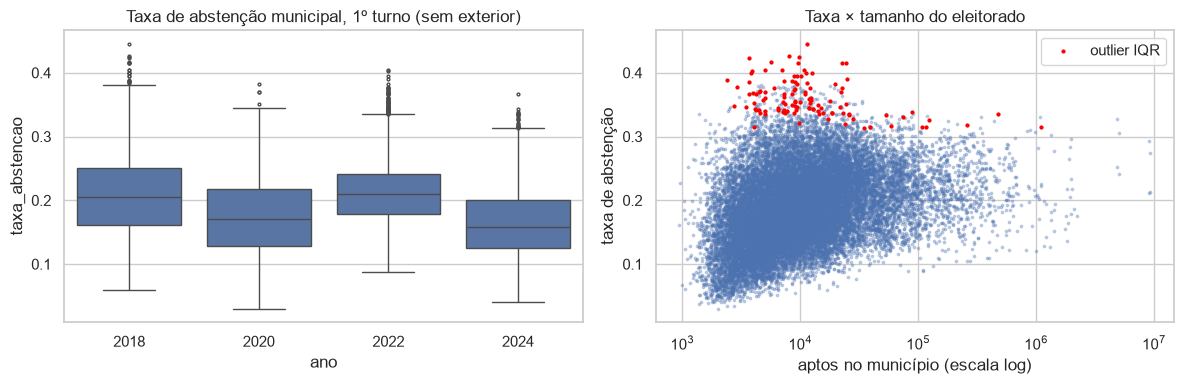

In [20]:
colunas_lista = ["ano", "sg_uf", "nm_municipio", "qt_aptos", "taxa_abstencao", "z"]
print("Maiores taxas (fora do exterior), por ano:")
display(br.sort_values("taxa_abstencao", ascending=False).groupby("ano").head(3)[colunas_lista].sort_values(["ano", "taxa_abstencao"], ascending=[True, False]).round(3))
print("Menores taxas, por ano:")
display(br.sort_values("taxa_abstencao").groupby("ano").head(3)[colunas_lista].sort_values(["ano", "taxa_abstencao"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=br, x="ano", y="taxa_abstencao", ax=axes[0], fliersize=2)
axes[0].set_title("Taxa de abstenção municipal, 1º turno (sem exterior)")
axes[1].scatter(br.qt_aptos, br.taxa_abstencao, s=3, alpha=.3)
axes[1].scatter(br.loc[br.out_iqr, "qt_aptos"], br.loc[br.out_iqr, "taxa_abstencao"], s=4, color="red", label="outlier IQR")
axes[1].set_xscale("log")
axes[1].set_xlabel("aptos no município (escala log)")
axes[1].set_ylabel("taxa de abstenção")
axes[1].legend()
axes[1].set_title("Taxa × tamanho do eleitorado")
plt.tight_layout()
plt.show()

Não há valor impossível: as taxas municipais vão de 2,9% a 44,5%. O limite inferior do IQR nunca é ultrapassado; todos os outliers estão acima do limite superior (21 em 2018, 4 em 2020, 63 em 2022 e 22 em 2024). O escore z marca menos casos (15, 3, 30 e 11), porque a distribuição tem cauda à direita.

Municípios pequenos não explicam os outliers: os que têm menos de 5 mil aptos são 25% a 29% do total, mas só 0% a 25% dos outliers. Os extremos são municípios médios (4 mil a 22 mil aptos) do Vale do Jequitinhonha em MG (Rio Vermelho aparece em 2020, 2022 e 2024; Chapada do Norte, Minas Novas, Sabinópolis) e do interior do Amazonas (Envira, Santa Isabel do Rio Negro, Maraã), além de Uruguaiana (RS) em 2024 e Oiapoque (AP) em 2020. São regiões de emigração e de grandes distâncias até a seção eleitoral, e a hipótese mais provável é que o cadastro guarde eleitores que já não moram no município. Nada nos números indica erro de carga. Os outliers ficam na base, marcados, e as médias usam taxas ponderadas pelos aptos.

O exterior é outra população: 59,1% de abstenção em 2018 e 51,7% em 2022, com mediana de 49% e 47% entre os 171–181 códigos. Somados, têm 0,5 a 0,7 milhão de aptos. Misturados aos municípios, seriam todos outliers e puxariam a taxa nacional para cima (20,33% contra 20,19% sem o exterior em 2018).

No boxplot, a mediana municipal é menor nas eleições municipais (17,1% e 15,8%) do que nas gerais (20,4% e 21,0%), embora a taxa nacional seja maior nas municipais. A diferença vem das cidades grandes, que se abstêm mais nas municipais, como mostram 2.4 e o painel da direita.

### 2.4 Análise bivariada e temporal

#### Taxa por ano e turno

O 2º turno das municipais só acontece em cidades com mais de 200 mil eleitores. Para comparar os turnos dentro do mesmo conjunto de municípios, a última coluna recalcula o 1º turno só para os municípios que tiveram 2º turno.

In [21]:
ano_turno = pd.concat([
    taxa_abstencao(mun_turno, ["ano", "tipo_eleicao"], turno=t).assign(nr_turno=t) for t in (1, 2)
])
com_t2 = mun_turno.loc[mun_turno.nr_turno.astype(int) == 2, ["ano", "cd_municipio"]]
t1_mesmos = taxa_abstencao(mun_turno.merge(com_t2, on=["ano", "cd_municipio"]), ["ano"], turno=1)
ano_turno = ano_turno.merge(t1_mesmos[["ano", "taxa_abstencao"]].rename(columns={"taxa_abstencao": "taxa_t1_mesmos_municipios"}), on="ano")
ano_turno.loc[ano_turno.nr_turno == 1, "taxa_t1_mesmos_municipios"] = np.nan
ano_turno = ano_turno.sort_values(["ano", "nr_turno"])[["ano", "tipo_eleicao", "nr_turno", "qt_aptos", "qt_abstencao", "taxa_abstencao", "taxa_t1_mesmos_municipios"]]

sem_zz = taxa_abstencao(mun_turno[mun_turno.sg_uf != "ZZ"], ["ano"], turno=1).rename(columns={"taxa_abstencao": "taxa_t1_sem_exterior"})
display(ano_turno.round(4))
sem_zz[["ano", "taxa_t1_sem_exterior"]].round(4)

,ano,tipo_eleicao,nr_turno,qt_aptos,qt_abstencao,taxa_abstencao,taxa_t1_mesmos_municipios
0,2018,geral,1,"147,306,275","29,940,386",0.2033,NaN
4,2018,geral,2,"147,306,275","31,367,981",0.2129,0.2033
1,2020,municipal,1,"147,918,483","34,241,451",0.2315,NaN
5,2020,municipal,2,"38,577,128","11,392,347",0.2953,0.2686
2,2022,geral,1,"156,454,011","32,739,676",0.2093,NaN
6,2022,geral,2,"156,454,011","32,186,397",0.2057,0.2093
3,2024,municipal,1,"155,912,680","33,797,125",0.2168,NaN
7,2024,municipal,2,"33,996,477","9,947,035",0.2926,0.2535


,ano,taxa_t1_sem_exterior
0,2018,0.2019
1,2020,0.2315
2,2022,0.2079
3,2024,0.2168


No 1º turno, a taxa foi de 20,3% em 2018, 23,1% em 2020, 20,9% em 2022 e 21,7% em 2024. As municipais ficam acima das gerais, e 2024 ficou 1,4 ponto acima de 2018, mas abaixo de 2020; não há crescimento contínuo. A série não tem resolução mensal: a base não traz data do evento (`DT_GERACAO` é a data de extração), então a unidade de tempo é a eleição, por ano e turno.

Nas gerais, o 2º turno tem o mesmo eleitorado, e a taxa quase não muda (21,3% contra 20,3% em 2018; 20,6% contra 20,9% em 2022). Nas municipais, a taxa nacional do 2º turno (29,5% e 29,3%) não é comparável à do 1º, porque só cidades grandes votam de novo. Nos mesmos municípios, o 2º turno tem 2,7 pontos a mais em 2020 (29,5% contra 26,9%) e 3,9 a mais em 2024 (29,3% contra 25,4%).

#### Por UF e região (1º turno)

A região vem da tabela de municípios do IBGE; o exterior aparece como "Exterior". A coluna `dif_2020` compara 2020 com a média dos outros três anos, e `dif_2020_vs_2024` compara 2020 com a outra eleição municipal.

In [22]:
regiao_uf = sql("SELECT DISTINCT sg_uf, nm_regiao FROM municipios_ibge")
mun_turno = mun_turno.merge(regiao_uf, on="sg_uf", how="left")
mun_turno["nm_regiao"] = mun_turno.nm_regiao.fillna("Exterior")

uf = taxa_abstencao(mun_turno, ["ano", "nm_regiao", "sg_uf"], turno=1)
uf_piv = uf.pivot(index=["nm_regiao", "sg_uf"], columns="ano", values="taxa_abstencao")
uf_piv["dif_2020"] = uf_piv[2020] - uf_piv[[2018, 2022, 2024]].mean(axis=1)
uf_piv["dif_2020_vs_2024"] = uf_piv[2020] - uf_piv[2024]
display((100 * uf_piv).round(1))

regiao = taxa_abstencao(mun_turno, ["ano", "nm_regiao"], turno=1).pivot(index="nm_regiao", columns="ano", values="taxa_abstencao")
display((100 * regiao).round(1))

so_br = (100 * uf_piv[ANOS]).drop(index="Exterior", level=0).droplevel(0)
br_reg = (100 * regiao).drop(index="Exterior")
ranking = pd.DataFrame({
    a: {"região mais alta": br_reg[a].idxmax(), "região mais baixa": br_reg[a].idxmin(),
        "4 UFs mais altas": ", ".join(f"{u} {v:.1f}" for u, v in so_br[a].dropna().nlargest(4).items()),
        "4 UFs mais baixas": ", ".join(f"{u} {v:.1f}" for u, v in so_br[a].dropna().nsmallest(4).items()),
        "UFs acima de 25%": ", ".join(so_br.index[so_br[a] > 25])}
    for a in ANOS})
ranking

ano                 2018  2020  2022  2024  dif_2020  dif_2020_vs_2024
nm_regiao    sg_uf                                                    
Centro-Oeste DF     18.7   NaN  17.6   NaN       NaN               NaN
             GO     20.2  23.4  21.7  23.4       1.6                -0
             MS     21.2  25.1  22.1  23.9       2.7               1.2
             MT     24.6  25.4  23.4  24.3       1.4               1.1
Exterior     ZZ     59.1   NaN  51.7   NaN       NaN               NaN
Nordeste     AL     22.6  21.6  22.4  19.9        -0               1.7
             BA     20.7  20.6  21.3  17.1       0.8               3.5
             CE     17.3  16.9  17.4  14.2       0.6               2.7
             MA     20.5  18.6  22.2    17      -1.3               1.6
             PB       15  15.8  17.3  15.4      -0.1               0.4
             PE     17.9  18.5  18.2  17.5       0.7                 1
             PI     15.7  15.4  17.7  14.8      -0.6               0.6
             RN     17.1  17.5  18.2  16.5       0.3                 1
             SE     18.8  18.6  18.3    17       0.5               1.6
Norte        AC       19  23.6  22.4  20.9       2.8               2.7
             AM     19.4    19  20.1  18.4      -0.3               0.6
             AP     16.7  24.2  19.5  20.5       5.3               3.7
             PA       20  20.1  21.2  17.3       0.6               2.7
             RO     22.3  27.8  24.6  25.9       3.5               1.9
             RR     13.9  21.2  16.7  18.1         5               3.1
             TO       20  17.2  18.5  16.4      -1.1               0.7
Sudeste      ES     19.3    24  20.8  23.5       2.9               0.5
             MG     22.2  23.2  22.3    23       0.7               0.2
             RJ     23.6  28.1  22.7  26.2       3.9               1.8
             SP     21.5  27.3  21.6  25.3       4.5                 2
Sul          PR       17  23.2  19.5    23       3.4               0.3
             RS     18.1  23.7  19.8  23.7       3.1                -0
             SC     16.3  22.5  18.5  21.7       3.6               0.8

ano,2018,2020,2022,2024
nm_regiao,,,,
Centro-Oeste,21,24.3,21.3,23.7
Exterior,59.1,NaN,51.7,NaN
Nordeste,18.8,18.5,19.5,16.5
Norte,19.7,20.7,20.9,18.6
Sudeste,22,26.3,22,24.9
Sul,17.3,23.2,19.3,22.9


,2018,2020,2022,2024
região mais alta,Sudeste,Sudeste,Sudeste,Sudeste
região mais baixa,Sul,Nordeste,Sul,Nordeste
4 UFs mais altas,"MT 24.6, RJ 23.6, AL 22.6, RO 22.3","RJ 28.1, RO 27.8, SP 27.3, MT 25.4","RO 24.6, MT 23.4, RJ 22.7, AC 22.4","RJ 26.2, RO 25.9, SP 25.3, MT 24.3"
4 UFs mais baixas,"RR 13.9, PB 15.0, PI 15.7, SC 16.3","PI 15.4, PB 15.8, CE 16.9, TO 17.2","RR 16.7, PB 17.3, CE 17.4, DF 17.6","CE 14.2, PI 14.8, PB 15.4, TO 16.4"
UFs acima de 25%,,"MS, MT, RO, RJ, SP",,"RO, RJ, SP"


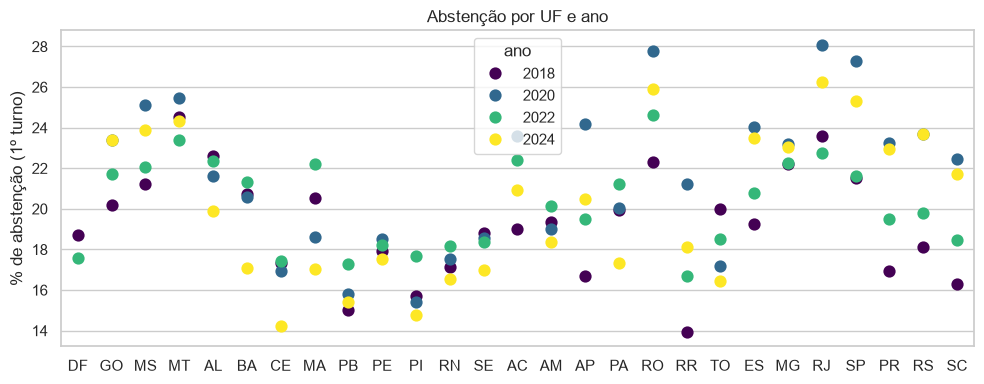

In [23]:
fig, ax = plt.subplots(figsize=(10, 4))
plot = (100 * uf_piv[ANOS]).drop(index="Exterior", level=0).reset_index().melt(id_vars=["nm_regiao", "sg_uf"], var_name="ano", value_name="taxa")
sns.pointplot(data=plot, x="sg_uf", y="taxa", hue="ano", linestyle="none", ax=ax, palette="viridis")
ax.set_ylabel("% de abstenção (1º turno)")
ax.set_xlabel("")
ax.set_title("Abstenção por UF e ano")
plt.tight_layout()
plt.show()

O Sudeste tem a maior taxa regional nos quatro anos (22,0% a 26,3%). A menor muda com o tipo de eleição: é o Sul nas gerais (17,3% em 2018 e 19,3% em 2022) e o Nordeste nas municipais (18,5% em 2020 e 16,5% em 2024).

Entre as UFs, RO, RJ e MT estão entre as quatro maiores em todos os anos. A ordem muda: MT lidera em 2018 (24,6%), RO em 2022 (24,6%) e RJ nas municipais (28,1% e 26,2%). Passam de 25% cinco UFs em 2020 (RJ, RO, SP, MT e MS) e três em 2024 (RJ, RO e SP). Na base, PB está entre as quatro menores em todos os anos, e PI em três deles (em 2022 é a quinta, com 17,7%). RR tem a menor taxa nas gerais (13,9% e 16,7%), mas não nas municipais (21,2% e 18,1%). CE fica entre as quatro menores em 2020, 2022 e 2024 (16,9%, 17,4% e 14,2%).

Sobre 2020: a taxa ficou acima da média dos outros anos em 20 das 26 UFs com dado, com saltos de 3 a 5 pontos no Sul, em SP, RJ, AP e RR. Mas 2024, a outra eleição municipal, ficou quase no mesmo patamar: a diferença 2020 − 2024 é de 0 a 2 pontos na maioria das UFs (Sul inteiro com no máximo 0,8), e só AP, BA, RR, CE, PA e AC passam de 2,5. Boa parte do "salto" de 2020 acompanha o tipo de eleição. Sobra uma diferença de cerca de 1,5 ponto no país (23,1% contra 21,7%), que pode refletir a pandemia; esta comparação não isola esse efeito de outras mudanças entre 2020 e 2024.

#### Faixa etária e escolaridade

A taxa por faixa etária e por escolaridade em cada ano, a taxa dos grupos de voto facultativo × obrigatório, e a tabela cruzada faixa × escolaridade (1º turno, quatro anos somados, ou seja, cada eleitor conta uma vez por eleição). As linhas com faixa `-3` ou escolaridade `0` ficam de fora.

In [24]:
perfil = sql('''
    SELECT ano, NR_TURNO, CD_FAIXA_ETARIA, DS_FAIXA_ETARIA, CD_GRAU_ESCOLARIDADE, DS_GRAU_ESCOLARIDADE,
           sum(QT_APTOS::BIGINT) AS QT_APTOS, sum(QT_ABSTENCAO::BIGINT) AS QT_ABSTENCAO,
           sum(QT_COMPAREC_FACULTATIVO::BIGINT + QT_ABST_FACULTATIVO::BIGINT) AS aptos_fac,
           sum(QT_ABST_FACULTATIVO::BIGINT) AS abst_fac,
           sum(QT_COMPAREC_OBRIGATORIO::BIGINT + QT_ABST_OBRIGATORIO::BIGINT) AS aptos_obr,
           sum(QT_ABST_OBRIGATORIO::BIGINT) AS abst_obr
    FROM tse WHERE CD_FAIXA_ETARIA <> '-3' AND CD_GRAU_ESCOLARIDADE <> '0'
    GROUP BY ALL''')
perfil.columns = perfil.columns.str.lower()
perfil["faixa"] = perfil.cd_faixa_etaria.astype(int).astype(str) + " " + perfil.ds_faixa_etaria
perfil["escolaridade"] = perfil.cd_grau_escolaridade + " " + perfil.ds_grau_escolaridade

faixa = taxa_abstencao(perfil, ["ano", "faixa"]).pivot(index="faixa", columns="ano", values="taxa_abstencao")
faixa.index = faixa.index.str.split(" ", n=1).str[1]
esc = taxa_abstencao(perfil, ["ano", "escolaridade"]).pivot(index="escolaridade", columns="ano", values="taxa_abstencao")
print("% de abstenção por faixa etária (1º turno)")
display((100 * faixa).round(1))
print("% de abstenção por escolaridade (1º turno)")
display((100 * esc).round(1))

t1 = perfil[perfil.nr_turno.astype(int) == 1].groupby("ano")[["aptos_fac", "abst_fac", "aptos_obr", "abst_obr", "qt_aptos"]].sum()
fac = pd.DataFrame({
    "pct_aptos_facultativos": 100 * t1.aptos_fac / t1.qt_aptos,
    "taxa_facultativo": 100 * t1.abst_fac / t1.aptos_fac,
    "taxa_obrigatorio": 100 * t1.abst_obr / t1.aptos_obr,
    "pct_da_abstencao_vinda_de_facultativos": 100 * t1.abst_fac / (t1.abst_fac + t1.abst_obr),
})
print("Voto facultativo × obrigatório (1º turno)")
fac.round(1)

% de abstenção por faixa etária (1º turno)


ano,2018,2020,2022,2024
faixa,,,,
16 anos,14.5,13.6,16.2,8.6
17 anos,17.8,17.3,17.7,11.9
18 anos,13.2,14.7,13.6,13.1
19 anos,17.8,19.8,18.8,19.7
20 anos,19.5,22.2,20.7,22.8
21 a 24 anos,21.1,24.2,23.5,26.5
25 a 29 anos,20.1,23.9,22.5,26.3
30 a 34 anos,18.3,22,19.8,23
35 a 39 anos,16.6,19.8,17.3,19.8


% de abstenção por escolaridade (1º turno)


ano,2018,2020,2022,2024
escolaridade,,,,
1 ANALFABETO,50.8,46.3,52.1,40.4
2 LÊ E ESCREVE,29,28.4,31.4,25.5
3 ENSINO FUNDAMENTAL INCOMPLETO,22.6,23.4,23.9,22.3
4 ENSINO FUNDAMENTAL COMPLETO,21.3,24.7,22.6,23.6
5 ENSINO MÉDIO INCOMPLETO,18.4,22.7,20.3,22
6 ENSINO MÉDIO COMPLETO,14.1,18.9,15.3,18.6
7 SUPERIOR INCOMPLETO,14.2,22.1,15.5,21.7
8 SUPERIOR COMPLETO,12.1,19.4,12.4,17.7


Voto facultativo × obrigatório (1º turno)


,pct_aptos_facultativos,taxa_facultativo,taxa_obrigatorio,pct_da_abstencao_vinda_de_facultativos
ano,,,,
2018,12.1,52.2,15.9,31.1
2020,12.7,53.4,18.8,29.2
2022,13.4,49.9,16.4,31.9
2024,13.2,42.9,18.5,26.1


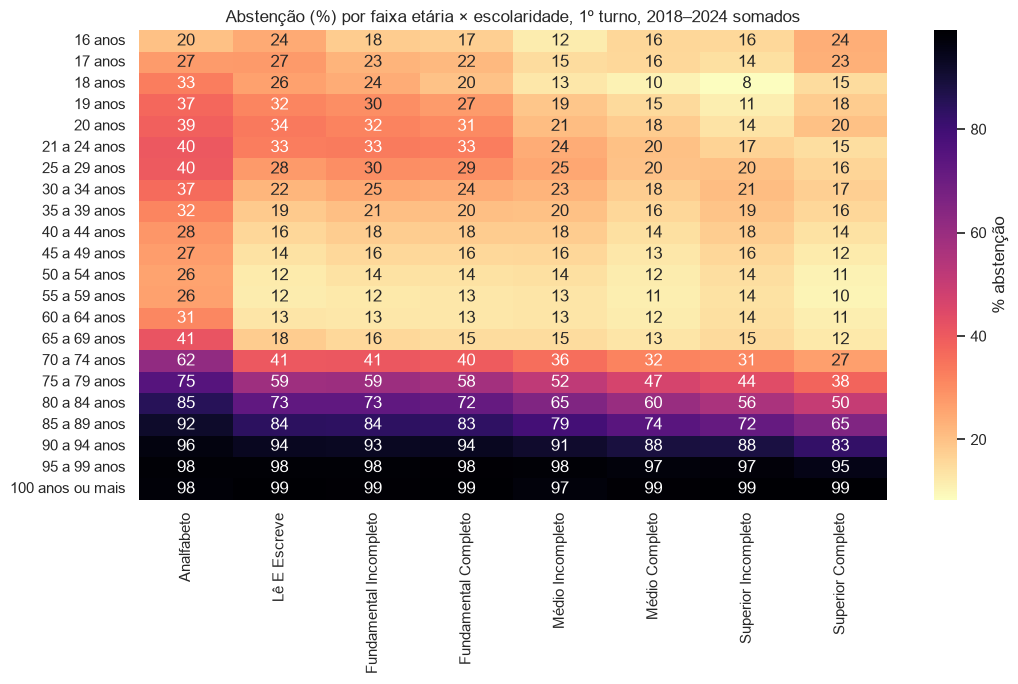

Faixas de 18 e de 40 a 44 anos (% de abstenção):


escolaridade,Analfabeto,Lê E Escreve,Fundamental Incompleto,Fundamental Completo,Médio Incompleto,Médio Completo,Superior Incompleto,Superior Completo
faixa,,,,,,,,
18 anos,33.1,26.4,24.1,20,12.7,10.5,8.3,14.8
40 a 44 anos,28.3,15.9,17.9,17.9,18.1,14.2,17.6,14


In [25]:
cruz = taxa_abstencao(perfil, ["faixa", "escolaridade"])
cruz_piv = cruz.pivot(index="faixa", columns="escolaridade", values="taxa_abstencao")
cruz_piv.index = cruz_piv.index.str.split(" ", n=1).str[1]
cruz_piv.columns = cruz_piv.columns.str.split(" ", n=1).str[1].str.replace("ENSINO ", "").str.title()
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(100 * cruz_piv, annot=True, fmt=".0f", cmap="magma_r", cbar_kws={"label": "% abstenção"}, ax=ax)
ax.set_title("Abstenção (%) por faixa etária × escolaridade, 1º turno, 2018–2024 somados")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
print("Faixas de 18 e de 40 a 44 anos (% de abstenção):")
(100 * cruz_piv.loc[["18 anos", "40 a 44 anos"]]).round(1)

A abstenção por idade tem forma de U. O ponto mais baixo fica entre 50 e 64 anos (12% a 16%); a faixa de 55 a 59 anos é a menor em todos os anos. Entre os jovens há um mínimo local aos 18 anos (13% a 15%), quase no mesmo nível. A taxa sobe entre os jovens adultos (21 a 29 anos: 20% a 27%) e cresce muito a partir dos 70: 34% a 47% aos 70–74 anos e mais de 95% acima dos 95 anos. Acima de 70 anos o voto é facultativo, o que explica parte da alta. Taxas perto de 100% nas faixas mais velhas levantam uma hipótese, não testada aqui contra registros de óbito ou contra a população por idade: o cadastro pode manter como aptos eleitores que já morreram ou não têm mais como votar, o que inflaria o denominador. Os jovens de 16 e 17 anos, também facultativos, se abstêm pouco (8,6% e 11,9% em 2024).

Os eleitores facultativos são 12% a 13% dos aptos. Sua taxa de abstenção (43% a 53%) é cerca de três vezes a dos obrigatórios (16% a 19%), e eles respondem por 26% a 32% de toda a abstenção.

A escolaridade tem gradiente claro nas gerais: de 51% a 52% entre analfabetos a 12% no superior completo. Nas municipais, o gradiente achata no topo: superior completo fica em 19% (2020) e 18% (2024), e superior incompleto passa do médio completo. A tabela cruzada mostra que parte do gradiente vem da idade (analfabetos são mais velhos), mas que ele persiste dentro de cada faixa: entre 40 e 44 anos, a taxa cai de 28% (analfabeto) para 14% (superior completo).

#### Correlação com variáveis do IBGE

A tabela municipal junta, por ano e só no 1º turno: taxa de abstenção, população e PIB per capita do IBGE, e três proporções do eleitorado do TSE (70 anos ou mais, 16–17 anos e superior completo). A junção usa o de-para; os códigos sem par são contados antes de sair da análise. Como as distribuições de população e PIB são muito assimétricas, a correlação principal é a de Spearman (postos).

In [26]:
comp = sql('''
    SELECT ano, CD_MUNICIPIO AS cd_municipio, sum(QT_APTOS::BIGINT) AS aptos,
           sum(QT_APTOS::BIGINT) FILTER (WHERE CD_FAIXA_ETARIA::INT >= 7074) AS aptos_70_mais,
           sum(QT_APTOS::BIGINT) FILTER (WHERE CD_FAIXA_ETARIA IN ('1600', '1700')) AS aptos_16_17,
           sum(QT_APTOS::BIGINT) FILTER (WHERE CD_GRAU_ESCOLARIDADE = '8') AS aptos_superior
    FROM tse WHERE NR_TURNO = '1' AND SG_UF <> 'ZZ' GROUP BY ALL''')
for c in ["70_mais", "16_17", "superior"]:
    comp[f"pct_{c}"] = 100 * comp[f"aptos_{c}"].fillna(0) / comp.aptos

depara = sql("SELECT * FROM depara_tse_ibge")
pop = sql("SELECT cd_municipio_ibge, ano, populacao FROM populacao_municipios")
pib = sql("SELECT cd_municipio_ibge, ano_eleicao AS ano, pib_per_capita FROM pib_municipios")

base = mun[~mun.exterior].merge(comp, on=["ano", "cd_municipio"], how="left")
base = base.merge(depara, left_on="cd_municipio", right_on="cd_municipio_tse", how="left")
base = base.merge(pop, on=["cd_municipio_ibge", "ano"], how="left").merge(pib, on=["cd_municipio_ibge", "ano"], how="left")
base["populacao"] = base.populacao.astype("float64")

juncao = base.groupby("ano").agg(
    municipios_tse=("cd_municipio", "size"),
    sem_depara=("cd_municipio_ibge", lambda s: int(s.isna().sum())),
    sem_populacao=("populacao", lambda s: int(s.isna().sum())),
    sem_pib=("pib_per_capita", lambda s: int(s.isna().sum())),
)
juncao["completos"] = base.dropna(subset=["cd_municipio_ibge", "populacao", "pib_per_capita"]).groupby("ano").size()
display(juncao)
print("Municípios por ano nas tabelas do IBGE e faixa do PIB per capita (R$):")
display(sql('''
    SELECT p.ano, p.municipios_populacao, p.populacao_nula, b.municipios_pib, b.pib_pc_min, b.pib_pc_max
    FROM (SELECT ano, count(DISTINCT cd_municipio_ibge) AS municipios_populacao,
                 count(*) FILTER (WHERE populacao IS NULL) AS populacao_nula
          FROM populacao_municipios GROUP BY ano) p
    LEFT JOIN (SELECT ano_eleicao AS ano, count(DISTINCT cd_municipio_ibge) AS municipios_pib,
                      round(min(pib_per_capita), 2) AS pib_pc_min, round(max(pib_per_capita), 2) AS pib_pc_max
               FROM pib_municipios GROUP BY ano_eleicao) b USING (ano)
    ORDER BY p.ano'''))

VARS = ["populacao", "pib_per_capita", "pct_70_mais", "pct_16_17", "pct_superior"]
completos = base.dropna(subset=VARS)
# Spearman = Pearson sobre os postos (evita depender do scipy).
spearman = pd.DataFrame({a: g[VARS].rank().corrwith(g.taxa_abstencao.rank()) for a, g in completos.groupby("ano")})
pearson_log = pd.DataFrame({
    a: g.assign(populacao=np.log10(g.populacao), pib_per_capita=np.log10(g.pib_per_capita))[VARS].corrwith(g.taxa_abstencao)
    for a, g in completos.groupby("ano")
})
print("Correlação de Spearman com a taxa de abstenção municipal (1º turno)")
display(spearman.round(3))
print("Pearson, com população e PIB per capita em log10")
pearson_log.round(3)

,municipios_tse,sem_depara,sem_populacao,sem_pib,completos
ano,,,,,
2018,5570,0,0,0,5570
2020,5568,0,0,0,5568
2022,5570,0,0,0,5570
2024,5569,1,1,1,5568


Municípios por ano nas tabelas do IBGE e faixa do PIB per capita (R$):


,ano,municipios_populacao,populacao_nula,municipios_pib,pib_pc_min,pib_pc_max
0,2018,5571,1,5570,"4,778","582,655"
1,2020,5571,1,5570,"4,921","590,595"
2,2021,5571,1,<NA>,NaN,NaN
3,2022,5570,0,5570,"6,757","842,005"
4,2024,5571,1,5570,"7,701","722,442"


Correlação de Spearman com a taxa de abstenção municipal (1º turno)


,2018,2020,2022,2024
populacao,0.163,0.647,0.194,0.587
pib_per_capita,-0.175,0.097,-0.146,0.199
pct_70_mais,0.329,0.131,0.165,0.021
pct_16_17,-0.171,-0.471,-0.01,-0.469
pct_superior,-0.488,0.093,-0.194,0.153


Pearson, com população e PIB per capita em log10


,2018,2020,2022,2024
populacao,0.098,0.628,0.122,0.588
pib_per_capita,-0.184,0.099,-0.153,0.188
pct_70_mais,0.327,0.109,0.149,0.012
pct_16_17,-0.174,-0.445,0.012,-0.448
pct_superior,-0.435,0.201,-0.173,0.23


Spearman entre as variáveis explicativas (2022)


,populacao,pib_per_capita,pct_70_mais,pct_16_17,pct_superior,taxa_abstencao
populacao,1,0.03,-0.27,-0.06,0.07,0.19
pib_per_capita,0.03,1,0.01,-0.57,0.6,-0.15
pct_70_mais,-0.27,0.01,1,-0.36,0.13,0.17
pct_16_17,-0.06,-0.57,-0.36,1,-0.47,-0.01
pct_superior,0.07,0.6,0.13,-0.47,1,-0.19
taxa_abstencao,0.19,-0.15,0.17,-0.01,-0.19,1


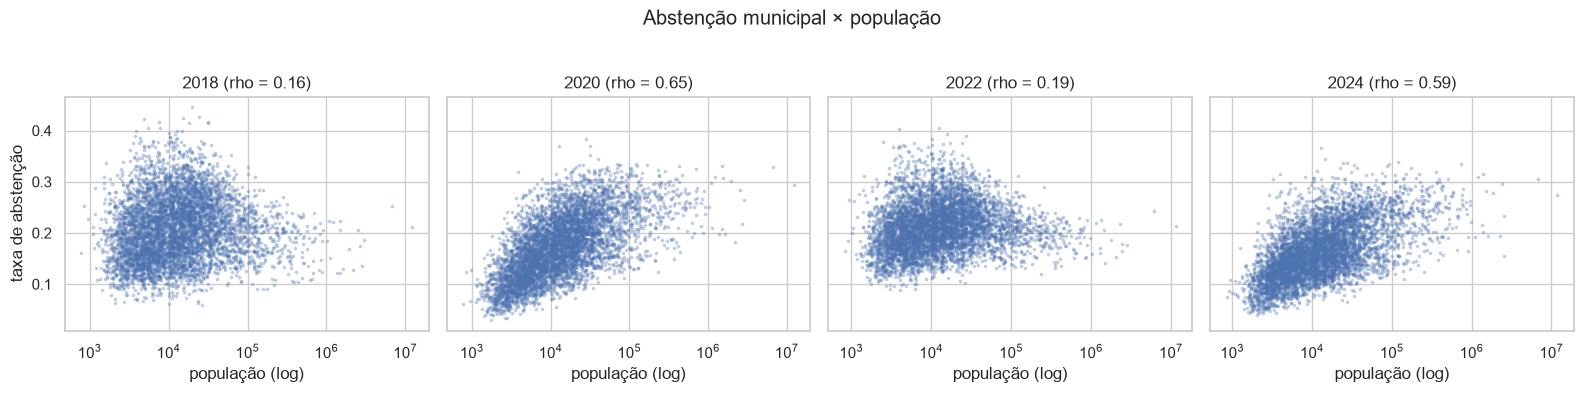

In [27]:
print("Spearman entre as variáveis explicativas (2022)")
display(completos[completos.ano == 2022][VARS + ["taxa_abstencao"]].rank().corr().round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (a, g) in zip(axes, completos.groupby("ano")):
    ax.scatter(g.populacao, g.taxa_abstencao, s=3, alpha=.25)
    ax.set_xscale("log")
    ax.set_title(f"{a} (rho = {spearman.loc['populacao', a]:.2f})")
    ax.set_xlabel("população (log)")
axes[0].set_ylabel("taxa de abstenção")
plt.suptitle("Abstenção municipal × população", y=1.03)
plt.tight_layout()
plt.show()

A junção perde um único município (Boa Esperança do Norte, em 2024, sem par no de-para). Os demais 5.568 a 5.570 municípios por ano têm população e PIB.

A população é a variável mais associada à abstenção, mas só nas eleições municipais: o Spearman é 0,65 em 2020 e 0,59 em 2024, contra 0,16 e 0,19 nas gerais. O PIB per capita tem correlação fraca e de sinal instável (−0,18 a 0,20). As proporções do eleitorado mudam de papel conforme o ano. A fração com superior completo tem correlação negativa nas gerais (−0,49 em 2018) e levemente positiva nas municipais. A fração de 16–17 anos é negativa nas municipais (−0,47); esta análise não separa essa associação do tamanho do município ou da região. As explicativas também se correlacionam entre si (PIB per capita × superior completo: 0,60 em 2022), então nenhuma dessas correlações isola um efeito.

### 2.5 Respostas preliminares às perguntas

1. Evolução, tipo de eleição e turno. A abstenção no 1º turno não cresceu de forma contínua: 20,3% (2018), 23,1% (2020), 20,9% (2022) e 21,7% (2024). As municipais ficam 1 a 3 pontos acima das gerais. O 2º turno das gerais tem taxa parecida com a do 1º (21,3% e 20,6%), enquanto o das municipais sobe 2,7 a 3,9 pontos em relação ao 1º turno dos mesmos municípios.
2. Idade e voto facultativo. A taxa tem forma de U por idade, com mínimo entre 50 e 64 anos (12% a 16%), um mínimo local aos 18 anos (13% a 15%), pico entre 21 e 29 anos (20% a 27%) e salto a partir dos 70 (34% a 47% aos 70–74, acima de 95% depois dos 95). Os facultativos (16–17, 70+ e analfabetos) são 12% a 13% do eleitorado, se abstêm 43% a 53% e respondem por 26% a 32% da abstenção total. Os de 16–17 anos se abstêm pouco (8,6% a 17,8%); o peso vem dos idosos.
3. Escolaridade. Há gradiente. Nas gerais, a taxa cai de 51% a 52% (analfabetos) para 12% (superior completo). Nas municipais o gradiente é mais fraco no topo (superior completo com 18% a 19%). O gradiente persiste dentro das faixas de idade.
4. UFs, regiões e 2020. O Sudeste tem a maior taxa nos quatro anos. A menor é do Sul nas gerais e do Nordeste nas municipais. RO, RJ e MT estão entre as quatro UFs mais altas em todos os anos, e PB entre as quatro mais baixas (PI em três dos quatro anos); RR é a mais baixa só nas gerais. 2020 ficou acima dos outros anos em 20 das 26 UFs, mas perto de 2024 (diferença nacional de 1,5 ponto). A maior parte da alta de 2020 acompanha o tipo de eleição. A diferença que sobra é maior em algumas UFs do Norte e do Nordeste e pode refletir a pandemia, mas esta análise não isola esse efeito.
5. População e PIB. Municípios mais populosos se abstêm mais, sobretudo nas municipais (Spearman 0,59 a 0,65; nas gerais, 0,16 a 0,19). O PIB per capita quase não tem relação com a taxa (|ρ| ≤ 0,20, com sinal que muda entre anos).

As respostas usam a bronze com as precauções já descritas (taxa por turno, exterior separado, sentinelas excluídas do perfil). Os números finais saem da silver, na Etapa 3.

### 2.6 Lista priorizada de problemas de qualidade

A ordem segue o impacto nas cinco perguntas. Cada linha vira um registro do log de limpeza da Etapa 3.

| # | problema | evidência (números) | impacto | decisão sugerida para a Etapa 3 |
|---|---|---|---|---|
| 1 | Eleitorado repetido entre turnos | Aptos do 2º turno = aptos do 1º em 100% dos municípios com 2º turno (5.741 em 2018, 5.751 em 2022, 58 em 2020, 51 em 2024); 147.306.275 aptos em cada turno de 2018 e 156.454.011 em 2022 | Somar `QT_APTOS` entre turnos dobra o denominador nas gerais. A taxa nacional do 2º turno municipal (29,5%/29,3%) não se compara à do 1º | Calcular toda taxa dentro de um turno (`taxa_abstencao(..., turno=)`). Manter `nr_turno` na silver e criar a marca `tem_2o_turno` por município e ano. Comparar turnos só no mesmo conjunto de municípios |
| 2 | Chave da linha não é única (células partidas) e "duplicados exatos" | Grupos com 2–3 linhas pela chave completa: 15.096 (2018), 12.664 (2020), 60.778 (2022), 40.574 (2024). Parte menor = 1 eleitor em 84%–94% dos grupos. Duplicados exatos: 21, 21, 276, 1.661. Desdobramento idêntico nos dois turnos (7.548 grupos em 2018, 30.389 em 2022) | A chave não identifica a linha, o que quebra junções e contagens de células. Remover duplicados exatos apagaria 1.979 linhas de eleitores reais | Não remover duplicados. Agregar somando todas as `QT_*` pela chave completa (ano, turno, UF, município, zona, `CD_*`). Validar que os totais de aptos, comparecimento e abstenção por ano e turno não mudam |
| 3 | Exterior (`ZZ`) misturado aos municípios | 171 (2018) e 181 (2022) códigos, 500.727 e 697.078 aptos, abstenção de 59,1% e 51,7%. Sem código IBGE. Só existe nas gerais, assim como DF | Vira outlier em toda análise municipal, eleva a taxa nacional (20,33% contra 20,19% em 2018) e não entra na junção com o IBGE | Criar a coluna `exterior`. Excluir das análises por município, UF e IBGE e mantê-lo no total nacional, sempre informado em separado. Registrar DF e `ZZ` ausentes nas municipais como ausência estrutural |
| 4 | Colunas de perfil que só existem em 2024 | Cor/raça, quilombola, Libras, identidade de gênero, idioma e grupo indígena: 100% `-1` em 2018–2022. Em 2024, cor/raça não informada em 43,8% das linhas e 89,8% dos aptos. Essas colunas elevam as células de 1 eleitor de 24% para 44% | Sem série temporal possível. Cor/raça cobre só 10% do eleitorado de 2024. As colunas fragmentam as células e quebram a chave comum entre anos | Converter `-1` em nulo. Tirar as seis colunas da tabela silver principal e reagregar 2024 pela chave comum aos quatro anos. Guardar uma tabela separada só de 2024 com essas colunas, se for usada |
| 5 | Sentinelas nas dimensões de perfil | Código `0` fora do LEIAME: estado civil 238.782 linhas, gênero 153.577, escolaridade 114.714. Faixa `-3` (Inválido): 13.579 linhas. No máximo 0,065% dos aptos por ano | Distorção pequena nas taxas por perfil. Sem tratamento, viram uma categoria espúria nos gráficos | Mapear `0` e `-3` para nulo, com rótulo único NÃO INFORMADO. Manter nos totais e excluir das análises por perfil, registrando quantos eleitores saíram |
| 6 | Possível denominador inflado nas faixas mais velhas (hipótese: cadastro desatualizado) | Abstenção de 77%–87% aos 85–89 anos, 88%–95% aos 90–94 e 96%–99% a partir dos 95. O voto facultativo acima de 70 anos explica parte disso; a hipótese do cadastro não foi testada contra óbitos ou população por idade | Se a hipótese se confirmar, a taxa dos 70+ e dos municípios com população mais velha fica superestimada (perguntas 2 e 5) | Manter os dados oficiais. Criar `grupo_idade` (16–17, 18–69, 70+) e incluir análise de sensibilidade sem 90+. Registrar a hipótese como limitação no relatório |
| 7 | Município sem par no de-para do TSE para o IBGE | Boa Esperança do Norte: TSE 73709 (MT, só em 2024) e IBGE 5101837 (MT, API de localidades), mesmo nome e UF, ausente do de-para. A população do IBGE para 5101837 é nula ou ausente em todos os anos e não há PIB. No IBGE, Brasília e Fernando de Noronha ficam sem eleição municipal | Perda de um município na junção de 2024. Contagens TSE e IBGE diferentes (5.568–5.570 contra 5.570–5.571) | Acrescentar o par 73709 → 5101837 ao de-para da silver, citando como fonte o nome e a UF no TSE e na API de localidades do IBGE. Manter o município fora das correlações enquanto o IBGE não publicar população e PIB. Documentar as ausências estruturais e relatar no log as linhas sem par depois da junção |
| 8 | Todas as colunas em texto | 43 colunas `VARCHAR`. Amostra de 1 milhão de linhas: 2.771 MB como texto contra 290 MB tipada (85,6 GB contra 9,0 GB extrapolado). Conversão sem perda em 100% das linhas | Memória e tempo: a base em texto não cabe na RAM desta máquina (15,4 GB). Risco de comparar códigos como texto (`'08'` ≠ `'8'`) | Tipar conforme o dicionário: `QT_*` `int32`, códigos `int8`/`int16`, `DS_*` e `SG_UF` `category`, `DT_GERACAO` `date`. Manter `cd_municipio` como texto de 5 caracteres. Renomear para snake_case |
| 9 | Falta o tipo de eleição; colunas redundantes | Não há coluna de tipo. `ANO_ELEICAO` = partição `ano` em 100% das linhas. `DT_GERACAO`/`HH_GERACAO` têm 1 valor por ano | Toda análise precisa saber se a eleição é geral ou municipal (perguntas 1 e 4) | Derivar `tipo_eleicao` (2018/2022 geral; 2020/2024 municipal). Descartar `ANO_ELEICAO` após o teste de igualdade e guardar `DT_GERACAO` e `HH_GERACAO` só nos metadados |
| 10 | Rótulos em forma inconsistente e nomes repetidos | Faixa etária em minúsculas ("16 anos", "Inválido"). Cor/raça, identidade de gênero e grupo indígena misturam caixa com NÃO INFORMADO. 5.751 códigos de município para 5.466 nomes | Gráficos e filtros por rótulo ficam frágeis. Junção por nome erraria municípios homônimos | Padronizar rótulos (maiúsculas, sem espaços extras) ou derivá-los dos códigos. Fazer junções só por código |
| 11 | Municípios com abstenção extrema | Outliers IQR (todos acima do limite): 21, 4, 63 e 22; z > 3: 15, 3, 30 e 11. Taxas entre 2,9% e 44,5%. Concentrados em municípios médios do Jequitinhonha (MG) e do interior do AM | Fenômeno real (emigração, distância). Removê-los esconderia exatamente os casos de interesse | Não remover. Criar a marca `outlier_iqr` por ano e usar taxas ponderadas pelos aptos e estatísticas robustas (mediana, Spearman) |
| 12 | Combinações implausíveis de perfil | Eleitores de 16–17 anos com superior completo: 246, 128, 1.074 e 159 linhas (dois turnos) | Ruído pequeno no cruzamento idade × escolaridade | Manter, marcar na validação da silver e relatar no log. Não corrigir a escolaridade |
| 13 | Variáveis do IBGE assimétricas e de fontes diferentes | População: estimativa (2018, 2020, 2024) e Censo (2022). PIB de 2023 usado em 2024. PIB per capita até R$ 842 mil | Correlações de Pearson ficam distorcidas, e a série tem uma quebra de fonte em 2022 | Usar log10 e Spearman. Guardar `fonte_populacao` e o ano do PIB na tabela integrada e citar a quebra no relatório |

## 3. Limpeza e tratamento

Esta seção aplica as decisões da lista priorizada (2.6) e grava a camada silver em `data/silver/tse/`, particionada por `ano=AAAA/sg_uf=XX` e comprimida com zstd. O código fica em `src/limpeza.py` e os testes em `tests/test_limpeza.py`.

A bronze em texto não cabe na memória, então o pipeline lê uma partição (ano × UF) por vez. A chave completa da linha inclui a UF, e por isso somar dentro de cada UF dá o mesmo resultado que somar o ano inteiro. A maior partição, SP 2024, tem 1,7 milhão de linhas e ocupa cerca de 0,5 GB durante o processamento.

Ordem das etapas em cada partição (entre parênteses, o item da lista 2.6):

1. `padronizar_colunas` e `tipar`: nomes em snake_case sem acento e tipos do dicionário de dados (item 8).
2. `tratar_sentinelas`: `-1`, `-3`, `#NULO#`, `#NE#` e o código `0` de gênero, estado civil e escolaridade viram nulo no `cd_*`, e o `ds_*` recebe o rótulo único NÃO INFORMADO. As colunas `qt_*` não passam por essa regra (itens 4 e 5).
3. `harmonizar_anos`: rótulos em maiúsculas e sem espaços extras (item 10).
4. `remover_redundantes`: confere `ano_eleicao` contra a partição, descarta a coluna e guarda data e hora de geração em `data/silver/tse_metadados.json` (item 9).
5. `agregar_por_chave`: soma as `qt_*` das células partidas pela chave completa (item 2).
6. `remover_perfil_2024`: tira as 12 colunas de perfil que só existem em 2024 e reagrega pela chave comum aos quatro anos (item 4).
7. `derivar`: `tipo_eleicao`, `nm_regiao`, `exterior`, `tem_2o_turno`, `faixa_etaria_agrupada`, `grupo_idade`, `voto_facultativo`, `data_turno` e `mes_ano` (itens 1, 3, 6 e 9).
8. `marcar_inconsistentes`: marca `inconsistente` (aptos ≠ comparecimento + abstenção) e `perfil_implausivel` (16–17 anos com superior completo), sem apagar linhas (item 12).
9. `integrar_ibge`: código IBGE pelo de-para com o par 73709 → 5101837 acrescentado, população do mesmo ano e PIB pela eleição associada, com `fonte_populacao` e `ano_pib` (itens 7 e 13).

`voto_facultativo` segue a Constituição (art. 14, § 1º, II): 16–17 anos, 70 anos ou mais, ou analfabeto. `data_turno` é a data oficial de cada turno no calendário do TSE, e `mes_ano` é o mês correspondente (AAAA-MM). As eleições de 2018, 2022 e 2024 foram em outubro; a de 2020 foi em novembro (dias 15 e 29), adiada pela Emenda Constitucional 107/2020 por causa da pandemia.

Duas variáveis ficam para a camada gold porque dependem de somar as células de um município. A marca `outlier_iqr` (item 11) é por município e ano. A taxa de abstenções por 100 mil habitantes (`abstencoes_por_100k_hab`) divide a abstenção do município pela sua população; numa linha da silver, que é uma célula de perfil dentro de uma zona, essa divisão não mede nada.

A construção completa leva de 7 a 12 minutos nesta máquina (pela linha de comando, `python -m src.limpeza`, é mais rápida que dentro do notebook; o tempo de cada execução aparece na saída da célula). Para não repetir esse tempo a cada execução do notebook, a célula abaixo só reconstrói a silver quando ela ou o log não existem, ou quando `REFAZER_SILVER = True`. A reconstrução é idempotente por ano: a pasta `ano=AAAA` é apagada antes de ser regravada.

In [28]:
from src.limpeza import (AUSENTES_PATH, LOG_PATH, METADADOS_PATH, SILVER_TSE,
                         ausentes_antes_depois, construir_silver)

REFAZER_SILVER = False  # True reconstrói a silver e o log mesmo que já existam

silver_pronta = LOG_PATH.exists() and all(any((SILVER_TSE / f"ano={a}").rglob("*.parquet")) for a in ANOS)
if REFAZER_SILVER or not silver_pronta:
    t0 = time.time()
    log = construir_silver(ANOS)
    log.salvar()
    print(f"silver construída em {time.time() - t0:.0f} s")
else:
    print(f"silver já existe em {SILVER_TSE.relative_to(RAIZ)}; log lido de {LOG_PATH.relative_to(RAIZ)} "
          "(REFAZER_SILVER = True para reconstruir)")

SILVER_GLOB = (SILVER_TSE / "**" / "*.parquet").as_posix()
con.execute(f"CREATE OR REPLACE VIEW silver AS SELECT * FROM read_parquet('{SILVER_GLOB}', hive_partitioning = true)")
print("metadados de geração:", METADADOS_PATH.read_text(encoding="utf-8").replace("\n", " "))

silver já existe em data\silver\tse; log lido de reports\log_limpeza.csv (REFAZER_SILVER = True para reconstruir)
metadados de geração: {   "2018": {     "dt_geracao": [       "2025-04-30"     ],     "hh_geracao": [       "07:09:09"     ]   },   "2020": {     "dt_geracao": [       "2025-04-30"     ],     "hh_geracao": [       "02:43:44"     ]   },   "2022": {     "dt_geracao": [       "2025-04-29"     ],     "hh_geracao": [       "22:31:40"     ]   },   "2024": {     "dt_geracao": [       "2025-04-29"     ],     "hh_geracao": [       "16:22:43"     ]   } }


### 3.1 Log de limpeza

Cada item da lista 2.6 tem pelo menos uma linha no log (`reports/log_limpeza.csv`). A coluna `unidade` diz o que as três contagens medem. Com `linhas`, `linhas_antes` e `linhas_depois` são as linhas na entrada e na saída da etapa, somadas sobre todas as partições. Com `celulas`, são as células das colunas examinadas (linhas × colunas): é o caso das sentinelas (itens 4 e 5) e dos rótulos (item 10), que mudam valores e não linhas. `linhas_afetadas` é a diferença quando a etapa junta linhas, a contagem marcada ou alterada quando ela marca, e 0 quando a etapa só converte tipos ou acrescenta colunas (itens 8 e 9, mês/ano, taxa por 100 mil).

In [29]:
log_limpeza = pd.read_csv(LOG_PATH)
with pd.option_context("display.max_colwidth", None, "display.float_format", "{:,.0f}".format):
    display(log_limpeza[["problema", "unidade", "linhas_antes", "linhas_depois", "linhas_afetadas"]])

,problema,unidade,linhas_antes,linhas_depois,linhas_afetadas
0,#1 Eleitorado repetido entre turnos,linhas,26310182,26310182,18458544
1,#2 Chave da linha não é única (células partidas),linhas,31633820,31504707,129113
2,#3 Exterior (ZZ) misturado aos municípios,linhas,26310182,26310182,141100
3,#4 Colunas de perfil que só existem em 2024 (-1 vira nulo),celulas,189802920,189802920,166443438
4,#4 Colunas de perfil que só existem em 2024 (remoção e reagregação),linhas,31504707,26310182,5194525
5,#5 Sentinelas nas dimensões de perfil (código 0 e faixa -3),celulas,126535280,126535280,520652
6,#6 Abstenção muito alta nas faixas mais velhas (cadastro desatualizado?),linhas,26310182,26310182,1283032
7,#7 Município sem par no de-para TSE → IBGE (par acrescentado),linhas,26310182,26310182,509
8,#7 Linhas sem par no IBGE depois da junção,linhas,26310182,26310182,141100
9,#8 Todas as colunas em texto,linhas,31633820,31633820,0


In [30]:
# Decisão e justificativa de cada linha do log (texto completo).
for _, r in log_limpeza.iterrows():
    print(f"{r.problema}\n  decisão: {r.decisao}\n  justificativa: {r.justificativa}\n")

#1 Eleitorado repetido entre turnos
  decisão: Manter nr_turno e criar tem_2o_turno (município teve 2º turno no ano). Toda taxa é calculada dentro de um turno.
  justificativa: Nas gerais o 2º turno repete os aptos do 1º em todos os municípios (147.306.275 em 2018). Somar aptos entre turnos dobraria o denominador. Afetadas = linhas marcadas com tem_2o_turno.

#2 Chave da linha não é única (células partidas)
  decisão: Somar todas as qt_* pela chave completa (ano, turno, UF, município, zona e códigos de perfil). Nenhum duplicado é apagado.
  justificativa: Os 1.979 duplicados exatos da EDA são pedaços de uma mesma célula, quase sempre com 1 eleitor. Apagá-los tiraria eleitores reais; somar devolve uma linha por chave com os mesmos totais. Afetadas = linhas absorvidas pela soma.

#3 Exterior (ZZ) misturado aos municípios
  decisão: Criar a coluna exterior e manter as linhas na silver, sem código IBGE e sem região.
  justificativa: Abstenção de 59,1% (2018) e 51,7% (2022) contra cerca de 

As etapas que mudam o número de linhas são duas. A soma das células partidas (item 2) junta 129.113 linhas, e a retirada das colunas de 2024 (item 4) junta mais 5.194.525, todas de 2024. As demais etapas só marcam ou convertem: 520.652 das 126.535.280 células de código das quatro dimensões de perfil viram nulo (item 5), 1.605 linhas recebem `perfil_implausivel` (item 12) e nenhuma linha viola aptos = comparecimento + abstenção.

Na junção com o IBGE, o par acrescentado para Boa Esperança do Norte casa 509 linhas de 2024 (item 7). As 141.100 linhas que continuam sem código IBGE são todas do exterior. A linha do item 13 conta 13.241.008 linhas cuja população vem do Censo (2022) ou cujo PIB é de outro ano (2024 usa o PIB de 2023).

### 3.2 Dados ausentes: critério e viés

Os critérios para valores ausentes estão no log. Esta parte mede o efeito de cada um sobre quem fica representado nas análises.

As linhas com código nulo em gênero, estado civil, idade ou escolaridade ficam nos totais e saem das análises por perfil. A célula mede o peso delas nos aptos e a diferença entre a abstenção delas e a dos demais.

In [31]:
# Quem sai das análises por perfil: peso nos aptos e taxa de abstenção (1º turno, sem exterior).
partes = []
for col in ["cd_genero", "cd_estado_civil", "cd_faixa_etaria", "cd_grau_escolaridade"]:
    partes.append(sql(f"""
        SELECT ano, '{col}' AS dimensao,
               100 * sum(qt_aptos) FILTER (WHERE {col} IS NULL) / sum(qt_aptos) AS pct_aptos_nulo,
               100 * sum(qt_abstencao) FILTER (WHERE {col} IS NULL) / sum(qt_aptos) FILTER (WHERE {col} IS NULL) AS taxa_nulo,
               100 * sum(qt_abstencao) FILTER (WHERE {col} IS NOT NULL) / sum(qt_aptos) FILTER (WHERE {col} IS NOT NULL) AS taxa_informado,
               100 * sum(qt_abstencao) / sum(qt_aptos) AS taxa_todos
        FROM silver WHERE nr_turno = 1 AND NOT exterior GROUP BY ano
    """))
vies = pd.concat(partes).sort_values(["dimensao", "ano"])
vies["efeito_pp"] = vies.taxa_informado - vies.taxa_todos  # quanto a taxa muda ao excluir os nulos
with pd.option_context("display.float_format", "{:.4f}".format):
    display(vies)

,ano,dimensao,pct_aptos_nulo,taxa_nulo,taxa_informado,taxa_todos,efeito_pp
0,2018,cd_estado_civil,0.0649,42.0543,20.1790,20.1932,-0.0142
1,2020,cd_estado_civil,0.0398,58.3173,23.1349,23.1489,-0.0140
2,2022,cd_estado_civil,0.0345,55.5779,20.7765,20.7885,-0.0120
3,2024,cd_estado_civil,0.0262,50.1370,21.6695,21.6770,-0.0075
0,2018,cd_faixa_etaria,0.0020,38.6997,20.1928,20.1932,-0.0004
1,2020,cd_faixa_etaria,0.0015,41.2172,23.1486,23.1489,-0.0003
2,2022,cd_faixa_etaria,0.0013,44.9421,20.7882,20.7885,-0.0003
3,2024,cd_faixa_etaria,0.0010,38.3065,21.6768,21.6770,-0.0002
0,2018,cd_genero,0.0432,42.5056,20.1835,20.1932,-0.0096
1,2020,cd_genero,0.0274,58.6400,23.1392,23.1489,-0.0097


Os eleitores sem gênero, estado civil ou escolaridade registrados se abstêm muito mais que os outros: 41% a 59% no 1º turno, contra 20% a 23% do eleitorado informado. As análises por perfil ficam, portanto, com os cadastros completos, que se abstêm menos. O grupo excluído é pequeno (no máximo 0,065% dos aptos), e a taxa dos informados fica no máximo 0,02 ponto percentual abaixo da taxa de todos (coluna `efeito_pp`), pouco demais para inverter qualquer comparação entre perfis.

A retirada das colunas de 2024 tem outro custo. A silver não permite estudar 2024 por cor/raça, quilombolas, Libras, identidade de gênero ou povos indígenas, e quem quiser fazer isso precisa voltar à bronze de 2024. Mesmo lá, quem declarou cor/raça é um grupo diferente do eleitorado:

In [32]:
# 2024: quem declarou cor/raça (bronze, 1º turno) se parece com o resto do eleitorado?
sql("""
    SELECT CASE WHEN CD_COR_RACA = '-1' THEN 'não declarou' ELSE 'declarou' END AS cor_raca,
           round(100 * sum(CAST(QT_APTOS AS BIGINT)) / sum(sum(CAST(QT_APTOS AS BIGINT))) OVER (), 1) AS pct_aptos,
           round(100 * sum(CAST(QT_ABSTENCAO AS BIGINT)) / sum(CAST(QT_APTOS AS BIGINT)), 1) AS taxa_abstencao
    FROM tse WHERE ano = 2024 AND NR_TURNO = '1' GROUP BY 1 ORDER BY 1
""")

,cor_raca,pct_aptos,taxa_abstencao
0,declarou,10.2,16.6
1,não declarou,89.8,22.3


Só 10,2% dos aptos de 2024 declararam cor/raça, e esse grupo se abstém 16,6%, contra 22,3% de quem não declarou. Uma taxa por cor/raça feita só com os informados descreve um grupo que vota mais que a média. Por isso o `-1` virou nulo e não uma categoria a mais.

`voto_facultativo` fica nulo para 11 mil a 34 mil aptos por ano, quase todos com escolaridade não informada (ver 3.4). O TSE conta todos eles como obrigatórios. Um analfabeto sem escolaridade registrada seria facultativo, então essa contagem do TSE subestima um pouco o grupo facultativo. O efeito é pequeno: o grupo se abstém de 15% a 19%, perto dos obrigatórios, e somá-lo a eles não muda a taxa dos obrigatórios na segunda casa decimal.

### 3.3 Totais antes e depois

Agregar as células partidas não pode mudar o eleitorado. A célula abaixo compara, por ano e turno, os totais de aptos, comparecimento e abstenção da bronze com os da silver e para com erro se algum diferir.

In [33]:
antes = sql("""
    SELECT ano, CAST(NR_TURNO AS TINYINT) AS nr_turno, count(*) AS linhas_bronze,
           sum(CAST(QT_APTOS AS BIGINT)) AS aptos, sum(CAST(QT_COMPARECIMENTO AS BIGINT)) AS comparecimento,
           sum(CAST(QT_ABSTENCAO AS BIGINT)) AS abstencao
    FROM tse GROUP BY ALL
""")
depois = sql("""
    SELECT ano, nr_turno, count(*) AS linhas_silver,
           sum(qt_aptos::BIGINT) AS aptos, sum(qt_comparecimento::BIGINT) AS comparecimento,
           sum(qt_abstencao::BIGINT) AS abstencao
    FROM silver GROUP BY ALL
""")
totais = antes.merge(depois, on=["ano", "nr_turno"], suffixes=("_bronze", "_silver")).sort_values(["ano", "nr_turno"])
for c in ["aptos", "comparecimento", "abstencao"]:
    totais[f"{c}_igual"] = totais[f"{c}_bronze"] == totais[f"{c}_silver"]
assert totais.filter(like="_igual").all().all(), "a limpeza mudou algum total"
assert totais.linhas_bronze.sum() == log_limpeza.query("unidade == 'linhas'").linhas_antes.max()
totais["reducao_linhas_%"] = 100 * (1 - totais.linhas_silver / totais.linhas_bronze)
display(totais[["ano", "nr_turno", "linhas_bronze", "linhas_silver", "reducao_linhas_%",
                "aptos_bronze", "aptos_silver", "comparecimento_igual", "abstencao_igual"]])

por_ano = totais.groupby("ano")[["linhas_bronze", "linhas_silver"]].sum()
por_ano.loc["total"] = por_ano.sum()
por_ano["reducao_%"] = 100 * (1 - por_ano.linhas_silver / por_ano.linhas_bronze)
por_ano

,ano,nr_turno,linhas_bronze,linhas_silver,reducao_linhas_%,aptos_bronze,aptos_silver,comparecimento_igual,abstencao_igual
2,2018,1,4188841,4181293,0.1802,"147,306,275","147,306,275",True,True
5,2018,2,4188841,4181293,0.1802,"147,306,275","147,306,275",True,True
0,2020,1,4261762,4252207,0.2242,"147,918,483","147,918,483",True,True
6,2020,2,383161,380052,0.8114,"38,577,128","38,577,128",True,True
1,2022,1,4392869,4362480,0.6918,"156,454,011","156,454,011",True,True
3,2022,2,4392869,4362480,0.6918,"156,454,011","156,454,011",True,True
4,2024,1,8964457,4284930,52.2,"155,912,680","155,912,680",True,True
7,2024,2,861020,305447,64.52,"33,996,477","33,996,477",True,True


,linhas_bronze,linhas_silver,reducao_%
ano,,,
2018,8377682,8362586,0.1802
2020,4644923,4632259,0.2726
2022,8785738,8724960,0.6918
2024,9825477,4590377,53.28
total,31633820,26310182,16.83


Os totais de aptos, comparecimento e abstenção são idênticos em todos os anos e turnos. A silver tem 26.310.182 linhas, 16,8% menos que a bronze (31.633.820). Quase toda a redução vem de 2024, que cai de 9.825.477 para 4.590.377 linhas (53%) quando as colunas de cor/raça, quilombola, Libras, identidade de gênero e indígenas deixam de partir as células. Nos outros anos, a redução fica entre 0,2% e 0,7% e vem só das células partidas.

### 3.4 Colunas derivadas e marcas

A tabela abaixo usa só o 1º turno, para não contar duas vezes o eleitorado das gerais. As duas últimas colunas mostram a data e o mês do 1º turno de cada ano: novembro em 2020 e outubro nos demais. Em seguida, `voto_facultativo` é conferido contra as colunas de facultativos e obrigatórios que o próprio TSE publica.

In [34]:
# Conferências das colunas derivadas e das marcas na silver inteira.
sql("""
    SELECT ano, any_value(tipo_eleicao) AS tipo_eleicao, count(*) AS linhas,
           count(*) FILTER (WHERE exterior) AS exterior,
           count(*) FILTER (WHERE tem_2o_turno) AS tem_2o_turno,
           count(*) FILTER (WHERE inconsistente) AS inconsistente,
           count(*) FILTER (WHERE perfil_implausivel) AS perfil_implausivel,
           count(*) FILTER (WHERE voto_facultativo IS NULL) AS facultativo_nulo,
           round(100 * sum(qt_aptos) FILTER (WHERE voto_facultativo) / sum(qt_aptos), 2) AS pct_aptos_facultativo,
           count(*) FILTER (WHERE cd_faixa_etaria IS NULL) AS faixa_nula,
           count(*) FILTER (WHERE nm_regiao IS NULL AND NOT exterior) AS sem_regiao_fora_exterior,
           string_agg(DISTINCT strftime(data_turno, '%d/%m/%Y'), ', ') AS data_turno,
           string_agg(DISTINCT mes_ano, ', ') AS mes_ano
    FROM silver WHERE nr_turno = 1 GROUP BY ano ORDER BY ano
""")

,ano,tipo_eleicao,linhas,exterior,tem_2o_turno,inconsistente,perfil_implausivel,facultativo_nulo,pct_aptos_facultativo,faixa_nula,sem_regiao_fora_exterior,data_turno,mes_ano
0,2018,geral,4181293,33640,4181293,0,123,15059,12.12,2779,0,07/10/2018,2018-10
1,2020,municipal,4252207,0,380052,0,116,7814,12.66,2100,0,15/11/2020,2020-11
2,2022,geral,4362480,36910,4362480,0,537,6858,13.37,1934,0,02/10/2022,2022-10
3,2024,municipal,4284930,0,305447,0,132,5424,13.17,1449,0,06/10/2024,2024-10


In [35]:
# voto_facultativo (derivado de idade e escolaridade) contra as contagens do próprio TSE.
fac = sql("""
    SELECT ano, voto_facultativo, sum(qt_aptos) AS aptos,
           sum(qt_comparec_facultativo + qt_abst_facultativo) AS facultativos_tse,
           sum(qt_comparec_obrigatorio + qt_abst_obrigatorio) AS obrigatorios_tse
    FROM silver WHERE nr_turno = 1 GROUP BY ALL ORDER BY ano, voto_facultativo
""")
# Linhas marcadas como facultativas devem ser 100% facultativas no TSE; as demais (False ou nulo), 100% obrigatórias.
eh_facultativo = fac.voto_facultativo.astype("boolean").fillna(False).astype(bool)
esperado = fac.facultativos_tse.where(eh_facultativo, fac.obrigatorios_tse)
assert (fac.aptos == esperado).all(), "voto_facultativo diverge das contagens do TSE"
fac

,ano,voto_facultativo,aptos,facultativos_tse,obrigatorios_tse
0,2018,False,"129,412,114",0,"129,412,114"
1,2018,True,"17,860,105","17,860,105",0
2,2018,<NA>,"34,056",0,"34,056"
3,2020,False,"129,169,181",0,"129,169,181"
4,2020,True,"18,732,451","18,732,451",0
5,2020,<NA>,"16,851",0,"16,851"
6,2022,False,"135,523,507",0,"135,523,507"
7,2022,True,"20,916,011","20,916,011",0
8,2022,<NA>,"14,493",0,"14,493"
9,2024,False,"135,374,883",0,"135,374,883"


A regra de idade e escolaridade reproduz exatamente a divisão do TSE. Os aptos marcados como facultativos (17,9 milhões em 2018 a 20,9 milhões em 2022) coincidem com a soma das colunas de facultativos, e os marcados como obrigatórios coincidem com a de obrigatórios. Ficam nulos de 11.560 a 34.056 aptos por ano, com idade inválida ou escolaridade não informada; o TSE trata todos eles como obrigatórios. A marca continua nula nesses casos, porque a silver não tem como saber a idade ou a escolaridade dessas pessoas. O viés dessa escolha está em 3.2.

### 3.5 Integração com o IBGE

Contagens por ano das linhas e municípios que ficaram sem código IBGE, população ou PIB depois da junção.

In [36]:
sem_par = sql("""
    SELECT ano,
           count(*) FILTER (WHERE cd_municipio_ibge IS NULL) AS linhas_sem_ibge,
           count(*) FILTER (WHERE cd_municipio_ibge IS NULL AND NOT exterior) AS linhas_sem_ibge_fora_exterior,
           count(DISTINCT cd_municipio) FILTER (WHERE cd_municipio_ibge IS NULL AND exterior) AS cod_exterior_sem_ibge,
           count(DISTINCT cd_municipio) FILTER (WHERE cd_municipio_ibge IS NULL AND NOT exterior) AS municipios_sem_ibge,
           count(DISTINCT cd_municipio_ibge) AS municipios_com_ibge,
           count(DISTINCT cd_municipio_ibge) FILTER (WHERE populacao IS NULL) AS com_ibge_sem_populacao,
           count(DISTINCT cd_municipio_ibge) FILTER (WHERE pib_per_capita IS NULL) AS com_ibge_sem_pib,
           any_value(fonte_populacao) FILTER (WHERE NOT exterior) AS fonte_populacao,
           max(ano_pib) AS ano_pib
    FROM silver GROUP BY ano ORDER BY ano
""")
sem_par

,ano,linhas_sem_ibge,linhas_sem_ibge_fora_exterior,cod_exterior_sem_ibge,municipios_sem_ibge,municipios_com_ibge,com_ibge_sem_populacao,com_ibge_sem_pib,fonte_populacao,ano_pib
0,2018,67280,0,171,0,5570,0,0,estimativa_6579,2018
1,2020,0,0,0,0,5568,0,0,estimativa_6579,2020
2,2022,73820,0,181,0,5570,0,0,censo_4709,2022
3,2024,0,0,0,0,5569,1,1,estimativa_6579,2023


In [37]:
# Quais municípios têm código IBGE mas ficam sem população ou PIB?
sql("""
    SELECT DISTINCT ano, sg_uf, cd_municipio, nm_municipio, cd_municipio_ibge, populacao, pib_per_capita
    FROM silver WHERE NOT exterior AND (populacao IS NULL OR pib_per_capita IS NULL)
    ORDER BY ano, cd_municipio
""")

,ano,sg_uf,cd_municipio,nm_municipio,cd_municipio_ibge,populacao,pib_per_capita
0,2024,MT,73709,BOA ESPERANÇA DO NORTE,5101837,<NA>,NaN


Nenhum município do TSE fica sem código IBGE: as únicas linhas sem código são as do exterior (171 códigos em 2018 e 181 em 2022). Os municípios com código são 5.570 nas gerais, 5.568 em 2020 e 5.569 em 2024. Só Boa Esperança do Norte (MT, IBGE 5101837) fica sem população e sem PIB, em 2024, porque o IBGE ainda não publica esses dados para o município. Ele continua na silver e sai das correlações com o IBGE.

### 3.6 Valores ausentes antes e depois

Percentual de linhas com valor ausente em cada coluna, sobre a base inteira. Na bronze, conta como ausente o nulo, qualquer valor de `SENTINELAS`, o código `0` de gênero, estado civil e escolaridade e o rótulo "Inválido" da faixa etária. Na silver, conta o nulo e o rótulo NÃO INFORMADO. Coluna removida aparece com `pct_ausente_depois` vazio, e coluna criada na silver, com `pct_ausente_antes` vazio. O resultado vai para `reports/ausentes_antes_depois.csv`. A tabela mostra só as colunas com algum ausente ou que existem em apenas uma das camadas.

In [38]:
t0 = time.time()
ausentes = ausentes_antes_depois()  # grava reports/ausentes_antes_depois.csv
print(f"ausentes medidos em {time.time() - t0:.0f} s sobre a bronze e a silver inteiras")
with pd.option_context("display.max_rows", 80, "display.float_format", "{:.3f}".format):
    display(ausentes[(ausentes.pct_ausente_antes.fillna(0) > 0) | (ausentes.pct_ausente_depois.fillna(0) > 0)
                     | ausentes.pct_ausente_antes.isna() | ausentes.pct_ausente_depois.isna()])

ausentes medidos em 11 s sobre a bronze e a silver inteiras


,coluna,pct_ausente_antes,pct_ausente_depois
0,dt_geracao,0.000,NaN
1,hh_geracao,0.000,NaN
2,ano_eleicao,0.000,NaN
7,cd_genero,0.485,0.584
8,ds_genero,0.485,0.584
9,cd_estado_civil,0.755,0.908
10,ds_estado_civil,0.755,0.908
11,cd_faixa_etaria,0.043,0.052
12,ds_faixa_etaria,0.043,0.052
13,cd_grau_escolaridade,0.363,0.436


As seis dimensões de 2024 tinham de 82,6% (cor/raça, quilombola, Libras, identidade de gênero) a 99,7% (grupo indígena) das linhas sem informação e saíram da silver. Nas quatro dimensões de perfil que ficam, a fração de linhas com NÃO INFORMADO sobe um pouco (gênero de 0,49% para 0,58%, estado civil de 0,75% para 0,91%). Nenhum eleitor ganhou ou perdeu informação: a agregação junta mais linhas entre as células informadas do que entre as não informadas, e o percentual por linha sobe.

Entre as colunas novas, `cd_municipio_ibge` e `nm_regiao` faltam em 0,54% das linhas, que são o exterior. População e PIB faltam em 0,54% (exterior mais as 509 linhas de Boa Esperança do Norte). `voto_facultativo` é nulo em 0,23% das linhas.

### 3.7 Esquema e tamanho da silver

In [39]:
import pyarrow.dataset as pads

esquema = pads.dataset(SILVER_TSE, format="parquet", partitioning="hive").schema
print(f"{len(esquema.names)} colunas na silver (incluindo as partições ano e sg_uf)")
print(esquema.to_string(show_schema_metadata=False))


def tamanho_mb(pasta):
    return sum(p.stat().st_size for p in Path(pasta).rglob("*.parquet")) / 2**20


print(f"\nbronze: {tamanho_mb(BRONZE / 'tse_parquet'):,.0f} MB em disco; "
      f"silver: {tamanho_mb(SILVER_TSE):,.0f} MB em disco")
silver_sp = pads.dataset(SILVER_TSE / "ano=2024" / "sg_uf=SP", format="parquet").to_table().to_pandas()
print(f"SP 2024 em memória (pandas, tipos da silver): {silver_sp.memory_usage(deep=True).sum() / 2**20:,.0f} MB "
      f"para {len(silver_sp):,} linhas")
silver_sp.dtypes.astype(str).value_counts()

46 colunas na silver (incluindo as partições ano e sg_uf)
nr_turno: int8
cd_municipio: string
cd_municipio_ibge: string
nm_municipio: dictionary<values=string, indices=int32, ordered=0>
nr_zona: int16
cd_genero: int8
ds_genero: dictionary<values=string, indices=int32, ordered=0>
cd_estado_civil: int8
ds_estado_civil: dictionary<values=string, indices=int32, ordered=0>
cd_faixa_etaria: int16
ds_faixa_etaria: dictionary<values=string, indices=int32, ordered=0>
cd_grau_escolaridade: int8
ds_grau_escolaridade: dictionary<values=string, indices=int32, ordered=0>
qt_aptos: int32
qt_comparecimento: int32
qt_abstencao: int32
qt_comparecimento_deficiencia: int32
qt_abstencao_deficiencia: int32
qt_comparecimento_tte: int32
qt_abstencao_tte: int32
qt_comparec_facultativo: int32
qt_abst_facultativo: int32
qt_comparec_obrigatorio: int32
qt_abst_obrigatorio: int32
qt_comparec_defic_facultativo: int32
qt_abst_defic_facultativo: int32
qt_comparec_defic_obrigatorio: int32
qt_abst_defic_obrigatorio: int

SP 2024 em memória (pandas, tipos da silver): 127 MB para 740,352 linhas


int32       16
category    11
bool         4
Int8         3
string       2
int16        2
int8         1
Int16        1
object       1
boolean      1
int64        1
float64      1
Name: count, dtype: int64

A silver tem 46 colunas tipadas, contando as partições `ano` e `sg_uf`. Os códigos de perfil são inteiros pequenos que aceitam nulo, os rótulos são categorias, as marcas são booleanas e `data_turno` é uma data. Em disco ela ocupa 197 MB, contra 217 MB da bronze, e a partição de SP 2024 (740.352 linhas) ocupa 127 MB no pandas.

Para as etapas seguintes ficam três regras. Calcular a taxa sempre dentro de um turno. Separar o exterior com `exterior` nas análises por município, UF e IBGE. Excluir as linhas com código nulo nas análises por perfil e informar quantos eleitores saíram. A marca `outlier_iqr`, as taxas por município e as abstenções por 100 mil habitantes entram na camada gold.

## 4. Visualizações

Nove figuras, uma por pergunta. O título de cada uma é a resposta e sai dos dados gold e dos relatórios de limpeza; os PNG ficam em `reports/figuras/`.

In [40]:
from IPython.display import Image, display

from src.graficos import (
    fig_01_abstencao_por_eleicao,
    fig_02_abstencao_por_uf,
    fig_03_abstencao_por_faixa_etaria,
    fig_04_distribuicao_por_regiao,
    fig_05_taxa_x_pib_populacao,
    fig_06_faixa_x_escolaridade,
    fig_07_mapa_municipal,
    fig_08_mapa_uf_variacao,
    fig_09_limpeza_antes_depois,
)

**Figura 1.** Taxa de abstenção do 1º turno e do 2º turno em cada eleição, de 2018 a 2024 (série temporal).

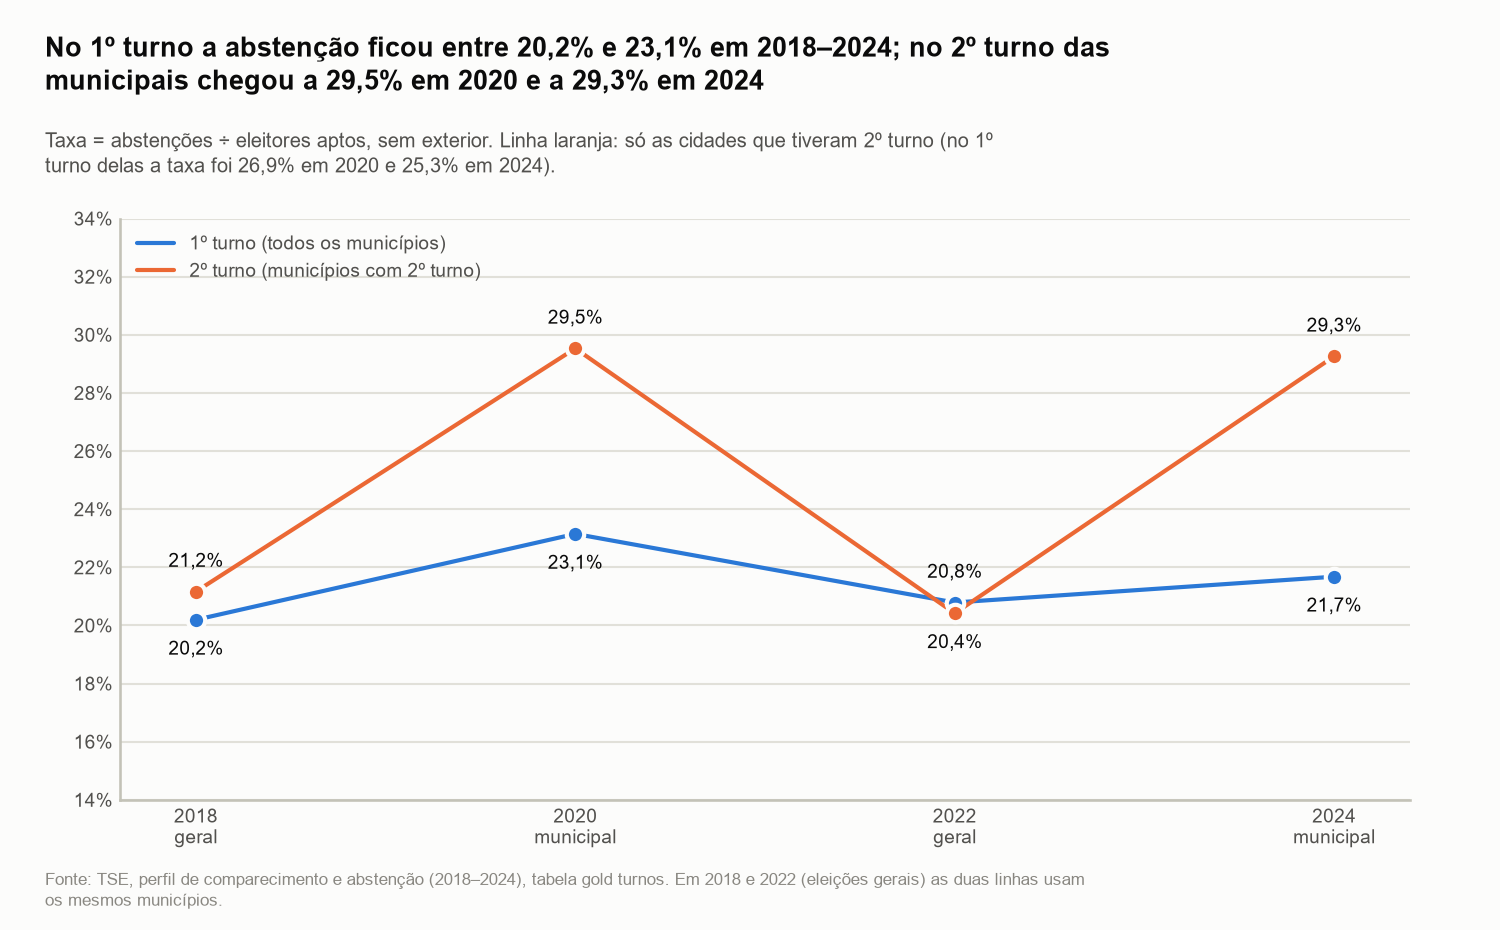

In [41]:
display(Image(filename=str(fig_01_abstencao_por_eleicao())))

**Figura 2.** Taxa de abstenção por UF em 2024, ordenada do menor para o maior valor (barras ordenadas).

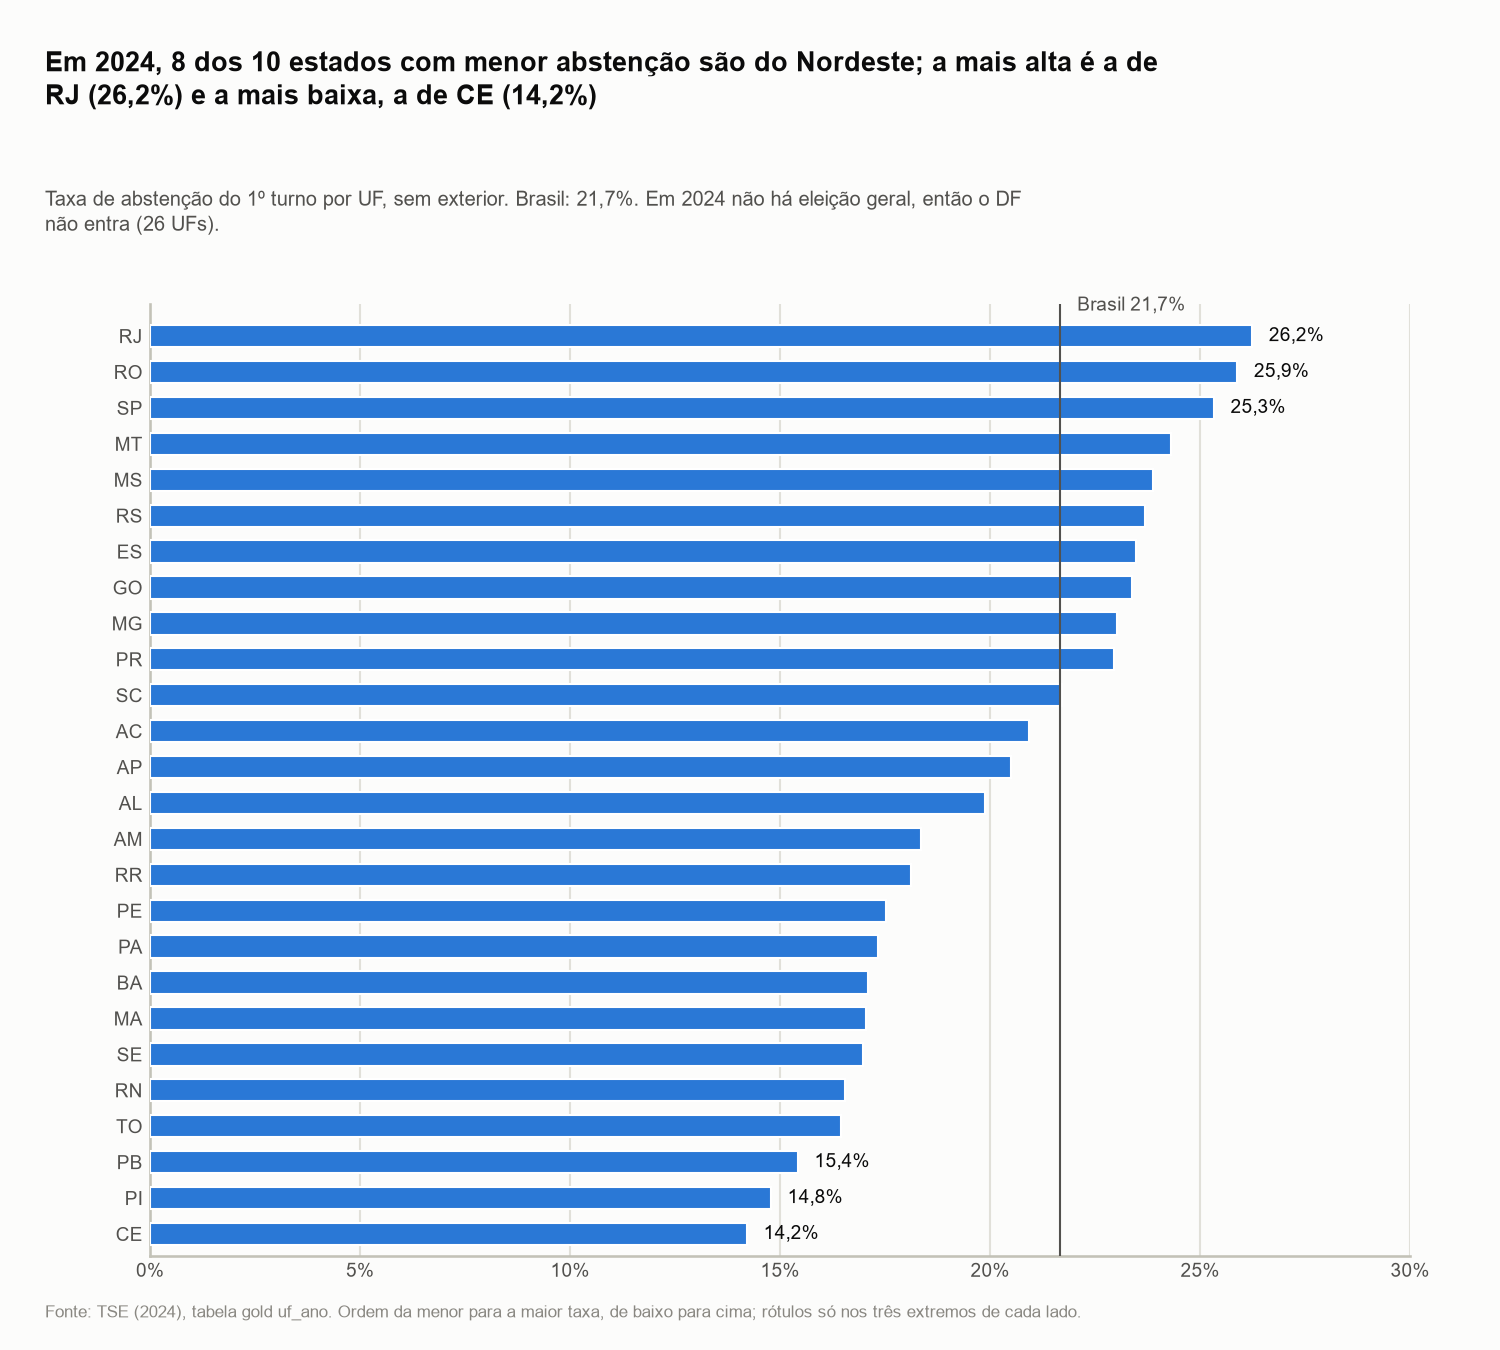

In [42]:
display(Image(filename=str(fig_02_abstencao_por_uf())))

**Figura 3.** Taxa de abstenção por faixa etária em 2024, com os grupos de voto facultativo destacados.

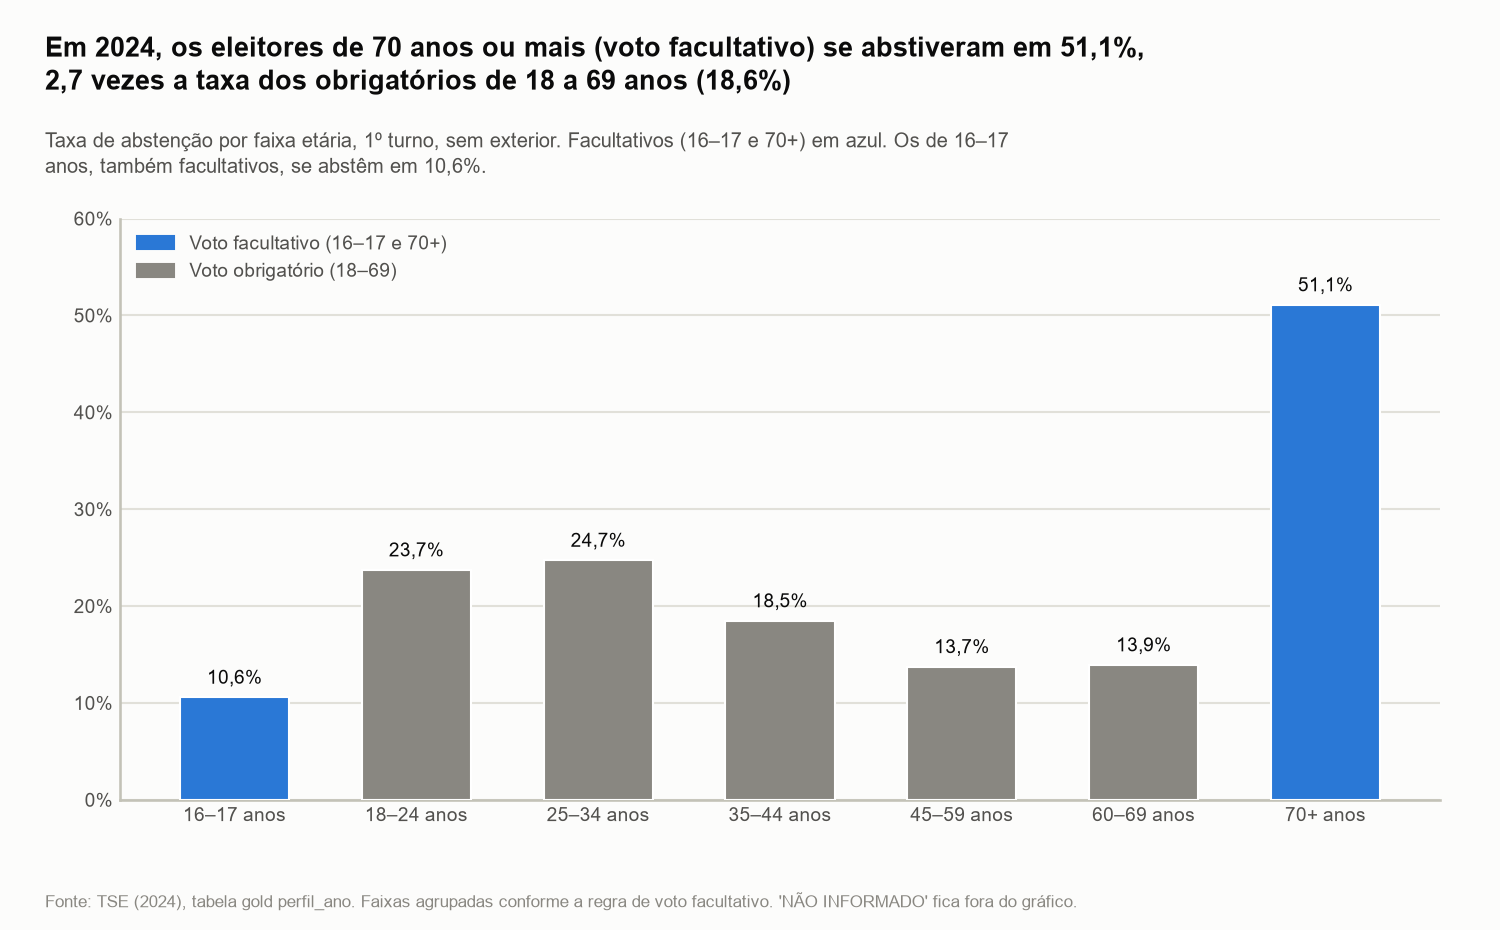

In [43]:
display(Image(filename=str(fig_03_abstencao_por_faixa_etaria())))

**Figura 4.** Distribuição da taxa municipal de abstenção em 2024 por região (caixa e um ponto por município).

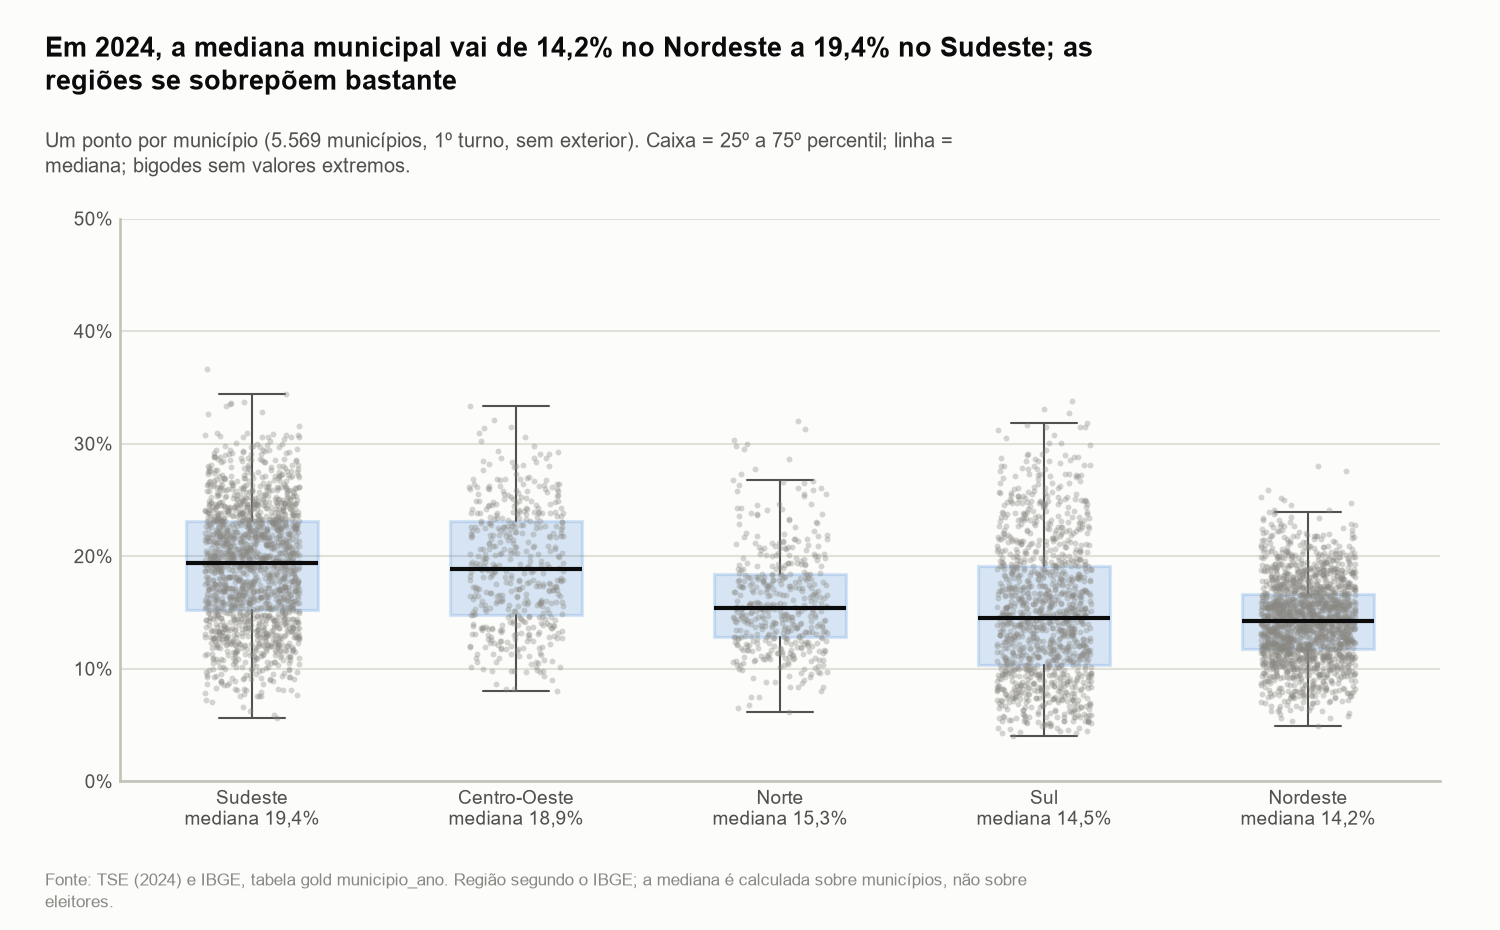

In [44]:
display(Image(filename=str(fig_04_distribuicao_por_regiao())))

**Figura 5.** Taxa municipal de abstenção contra PIB per capita e população em 2022, em escala log (dispersão).

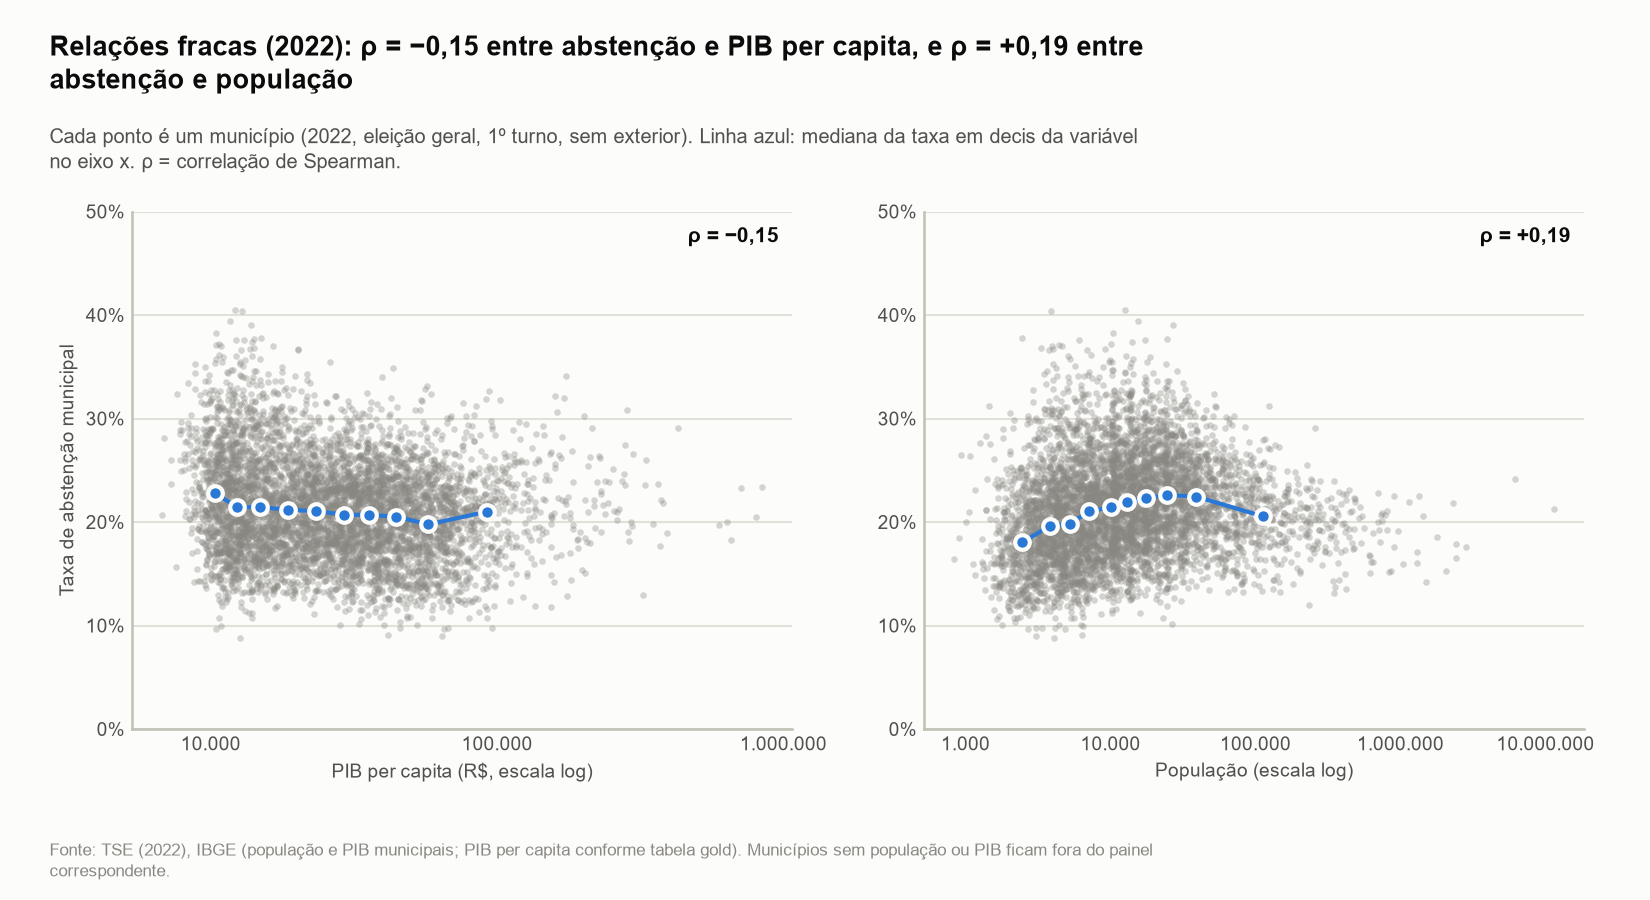

In [45]:
display(Image(filename=str(fig_05_taxa_x_pib_populacao())))

**Figura 6.** Taxa de abstenção em 2024 por faixa etária e escolaridade (mapa de calor).

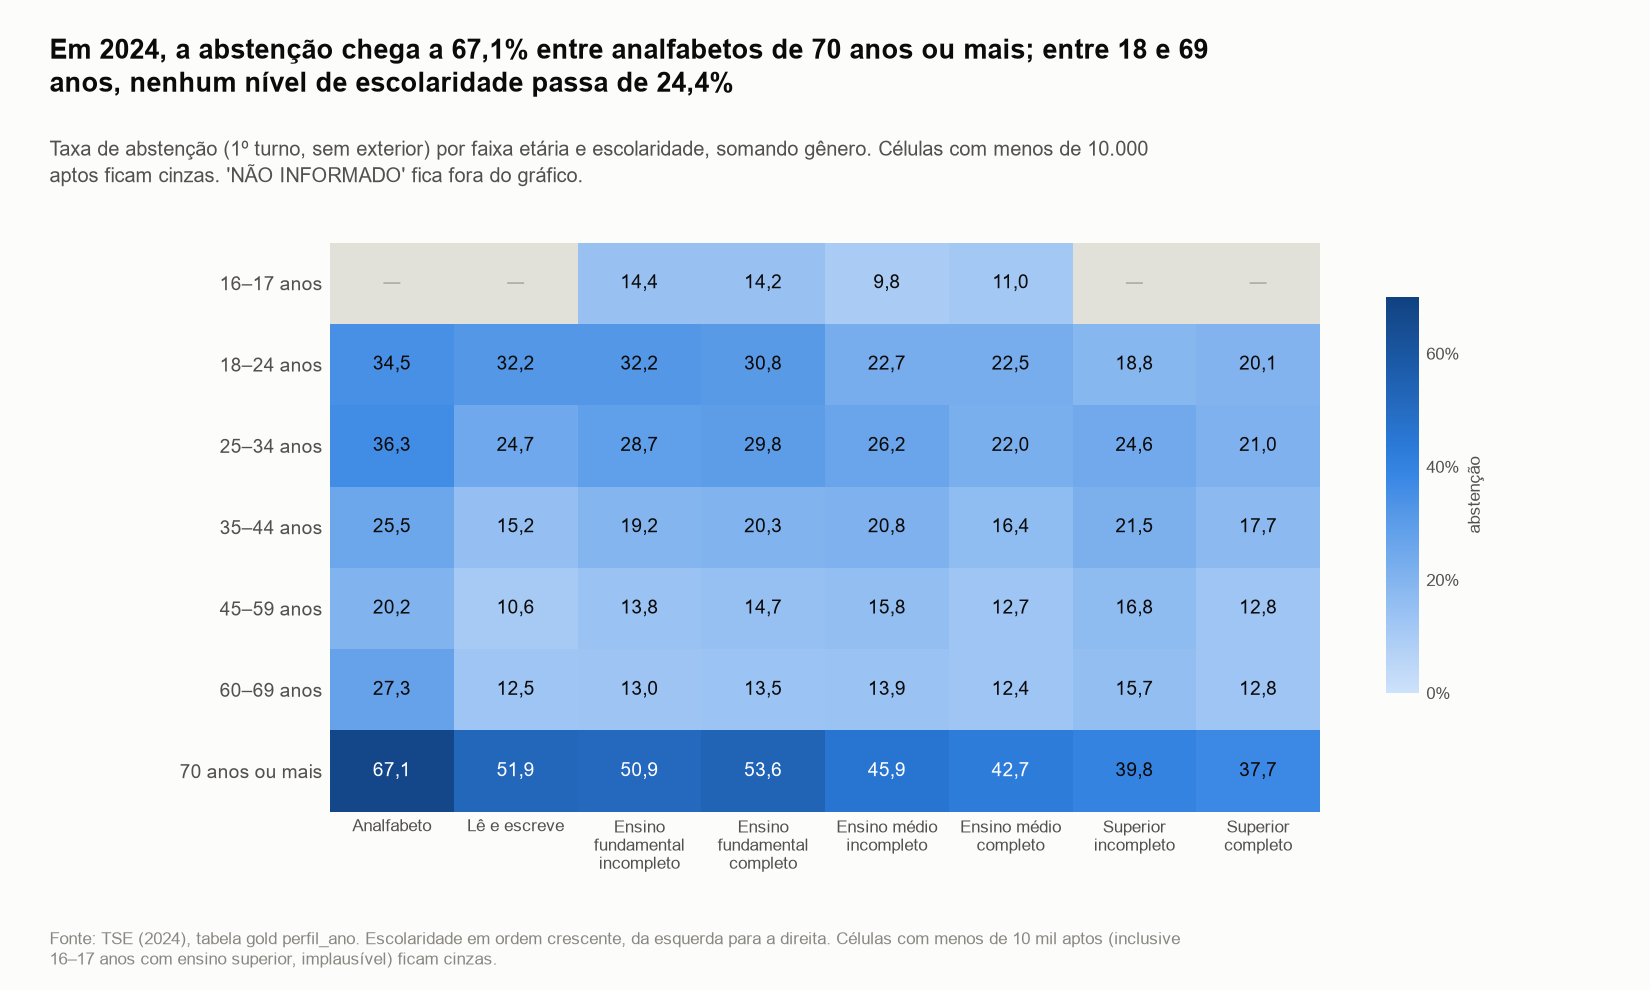

In [46]:
display(Image(filename=str(fig_06_faixa_x_escolaridade())))

**Figura 7.** Mapa municipal da taxa de abstenção do 1º turno em 2024 (coroplético). Os municípios sem par na malha estão no rodapé.

fig 07: 1 municípios do TSE sem malha; 2 malhas sem dado do TSE


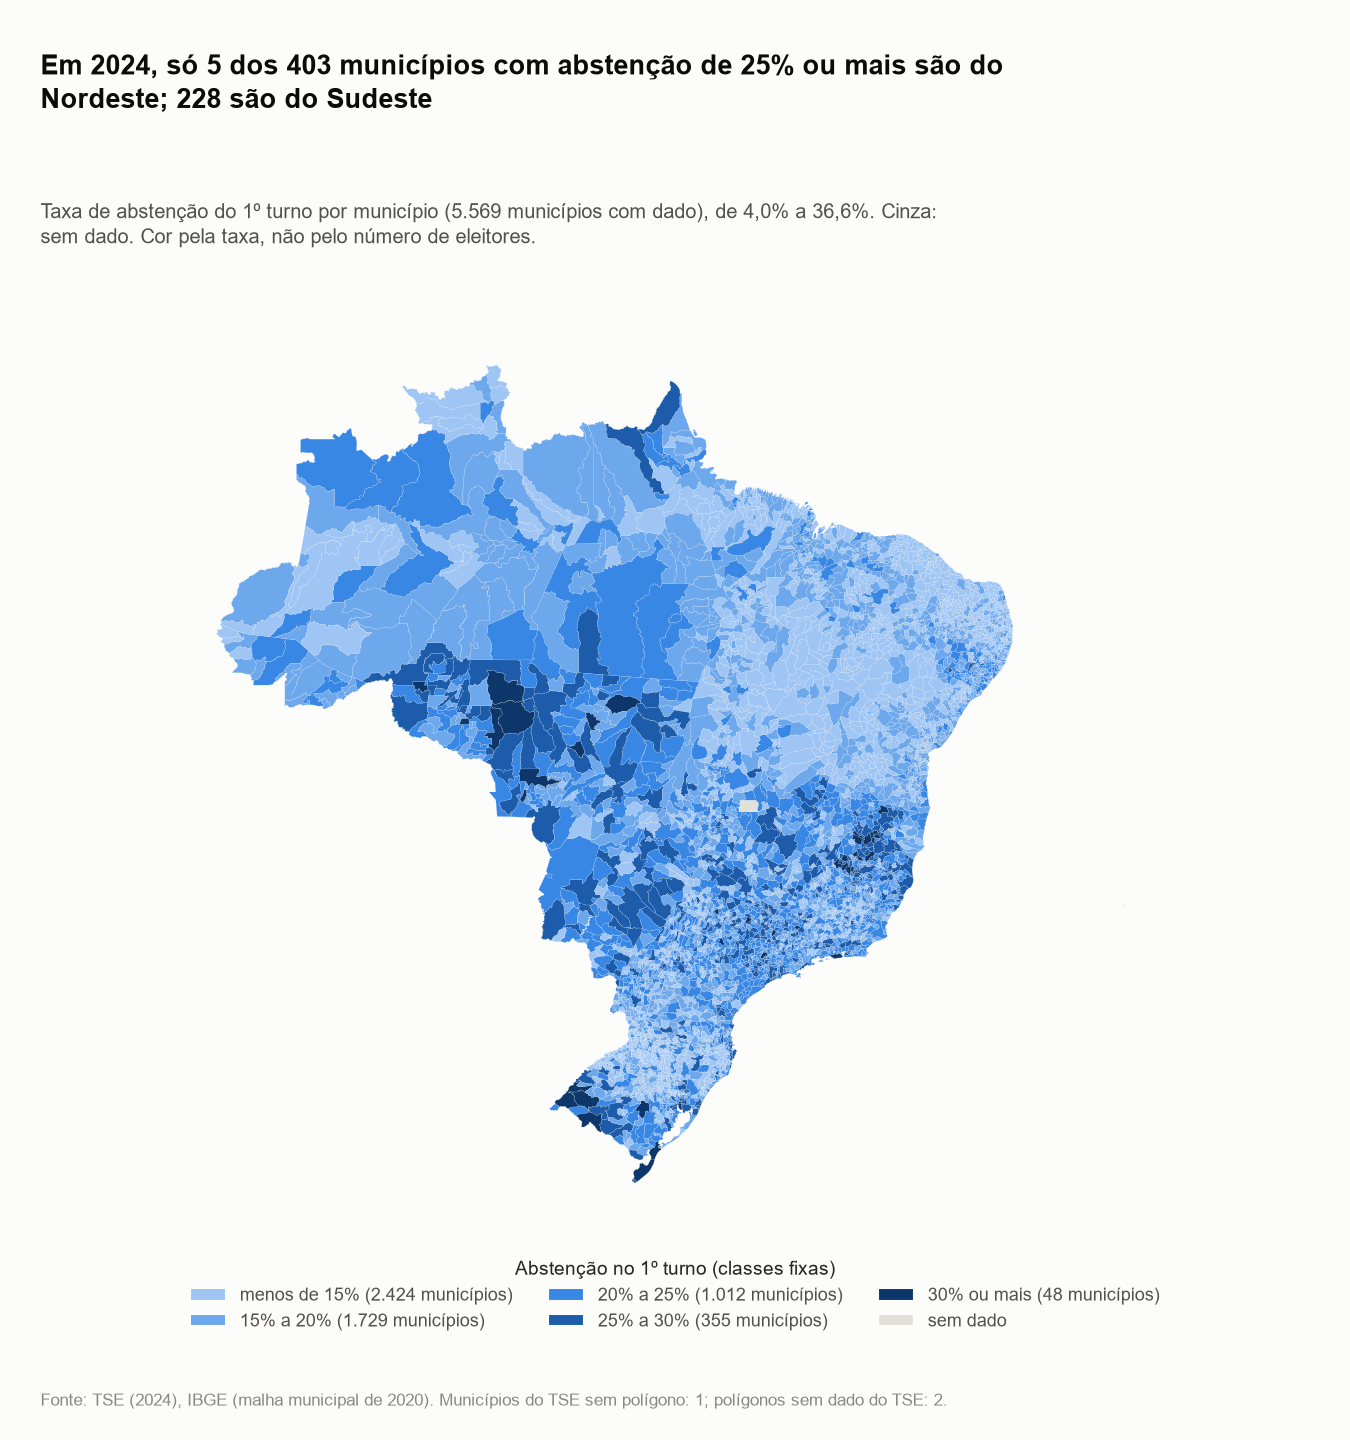

In [47]:
display(Image(filename=str(fig_07_mapa_municipal())))

**Figura 8.** Mapa por UF da variação da taxa de abstenção entre 2018 e 2022, em pontos percentuais (divergente, centrado em zero).

fig 08: 0 UF(s) do mapa sem dado


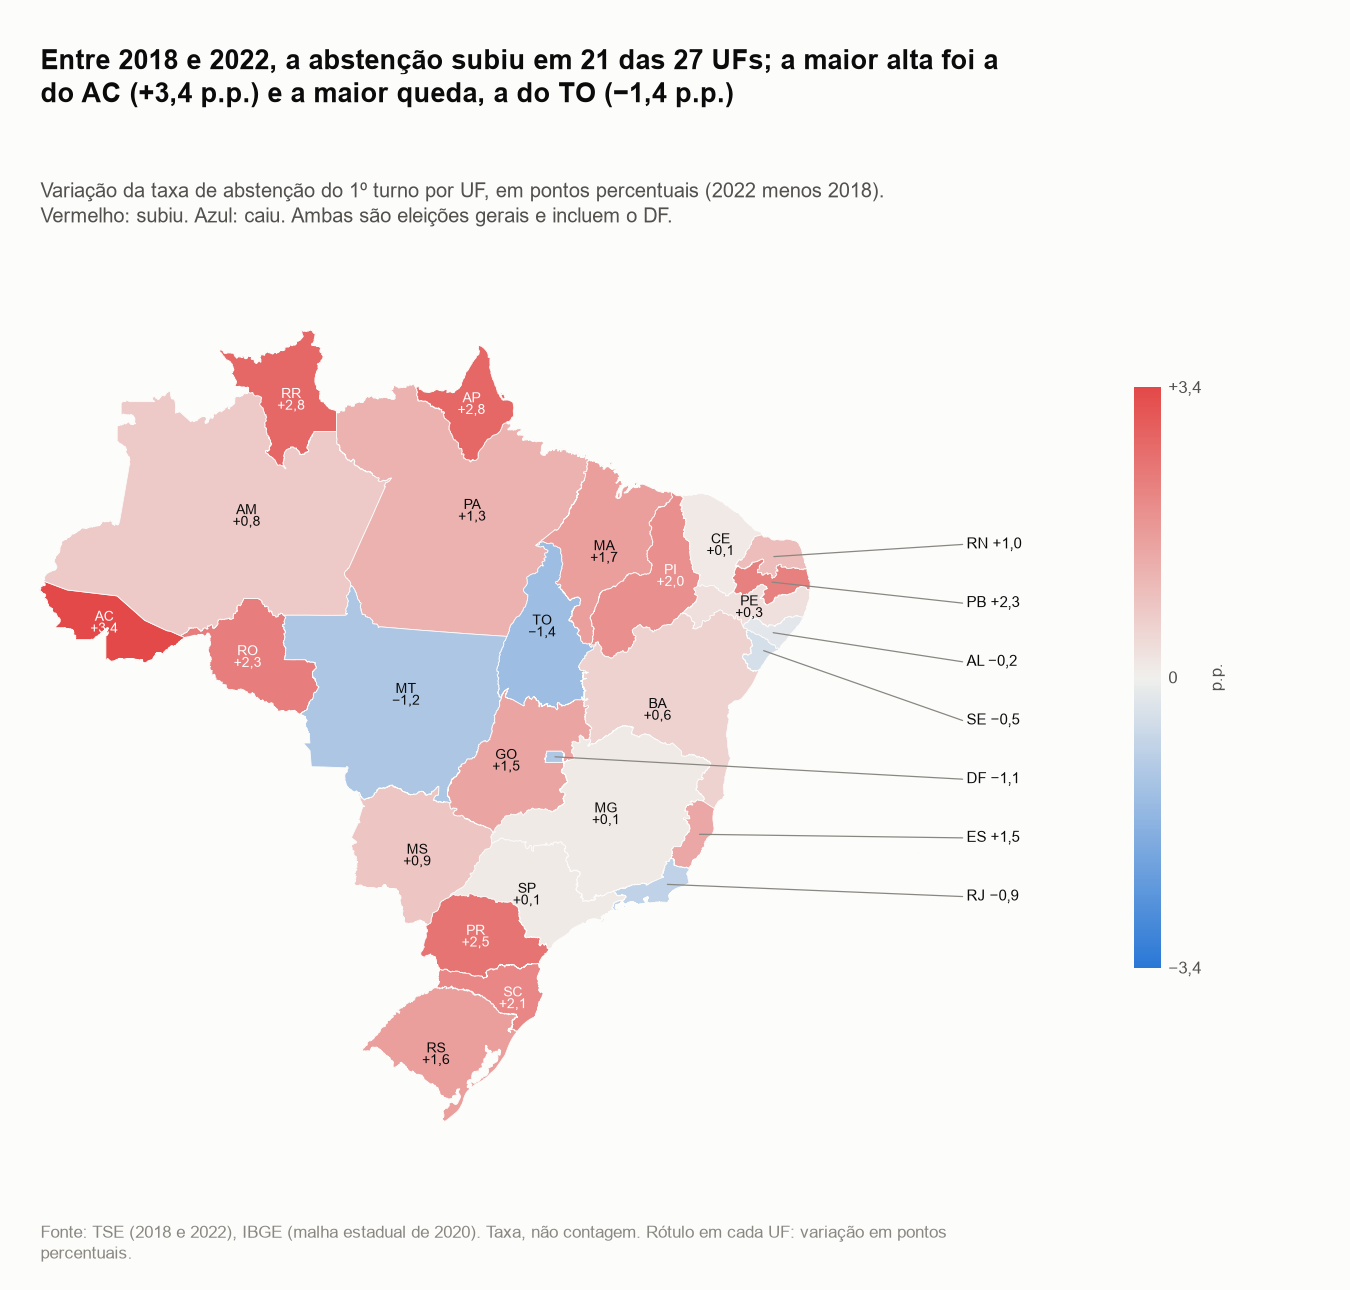

In [48]:
display(Image(filename=str(fig_08_mapa_uf_variacao())))

**Figura 9.** Linhas por etapa de limpeza e percentual de ausentes antes e depois, em painéis separados por unidade.

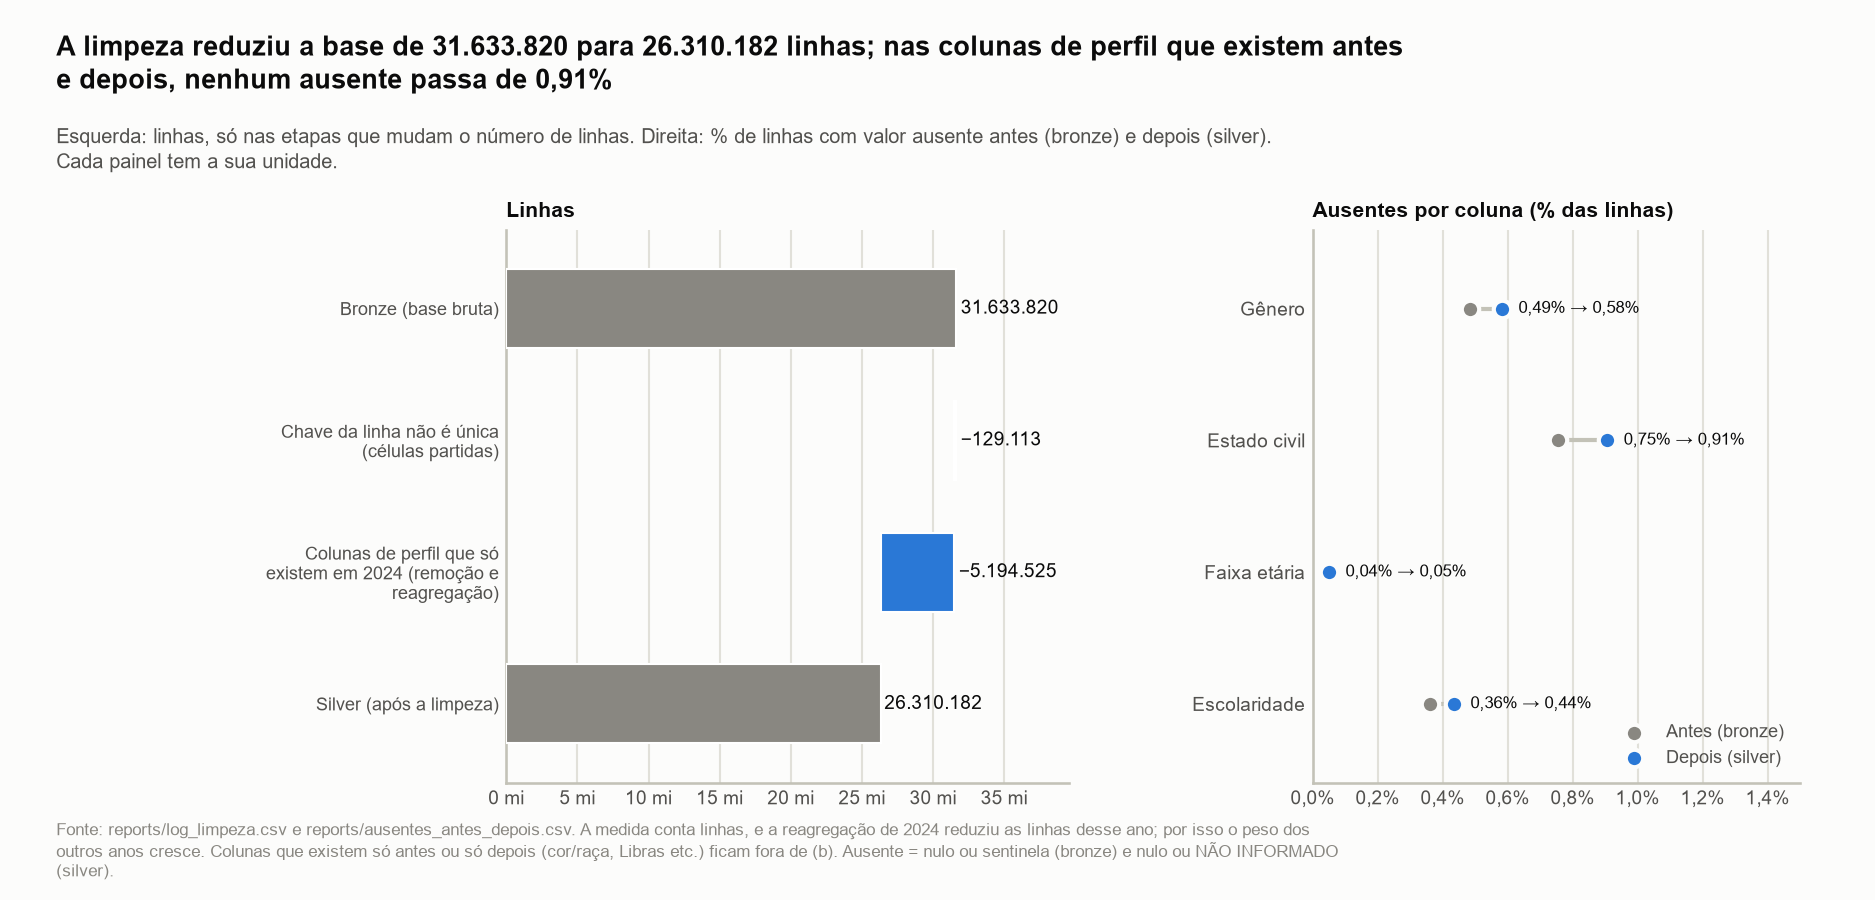

In [49]:
display(Image(filename=str(fig_09_limpeza_antes_depois())))